# AI-Driven Crop and Fertiliser Recommendation System
## Units 3, 4 and 5: selected algorithms, compared and chosen in MLflow

From each unit, only the algorithms that fit the project's goal are applied. In every unit the selected algorithms are tuned, compared on one common score, and the best one is chosen and registered in the MLflow Model Registry.

| Section | Unit | Project output | Algorithms applied | Score used to choose | MLflow experiment |
|---|---|---|---|---|---|
| 1-2 | - | Setup and data | - | - | - |
| **3** | **Unit 3** | Fertiliser zones from soil N, P, K | 3.1 K-means, 3.2 Hierarchical clustering, 3.3 Gaussian mixture model (EM) | ARI against the hidden fertility label | `Unit 3 - Clustering` |
| **4** | **Unit 4** | Next month's rainfall category | 4.1 Markov chain, 4.2 HMM (Baum-Welch), 4.3 HMM (Viterbi training), 4.4 Kalman filter (linear dynamical system) | Validation log-loss (1981-1995) | `Unit 4 - Sequential models (HMM)` |
| **5** | **Unit 5** | Crop recommendation and soil potassium estimate | 5.1 Random forest, 5.2 Extra trees, 5.3 Gradient boosting, 5.4 Stacking | Mean 5-fold CV score | `Unit 5 - Ensemble methods` |
| 6 | All | The chosen models, loaded back from the registry | - | - | - |

**How every choice is made.** Each algorithm first chooses its own best setting (one MLflow *child run* per setting tried). The algorithms are then compared in a **comparison and selection** run (3.4, 4.5, 5.5); the best one is registered as *champion* and the runner-up as *challenger*. Test data are only reported, never used to choose.

**Running locally.** Run all cells from top to bottom (about 10 minutes). Runs are stored in `mlflow.db` and `mlruns/` in this folder. Open the dashboard with `mlflow ui --backend-store-uri sqlite:///mlflow.db` and go to http://localhost:5000.

---
# 1. Setup
### 1.1 Install MLflow

In [1]:
!pip install -q "mlflow>=3.1"

### 1.2 MLflow tracking and the three unit experiments

In [2]:
import os
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'
os.environ['PYTHONWARNINGS'] = 'ignore'          # also silences warnings from parallel worker processes

import mlflow
mlflow.set_tracking_uri('sqlite:///mlflow.db')     # local tracking store in this folder
mlflow.sklearn.autolog(disable=True)               # everything is logged explicitly, nothing twice

EXP3 = 'Unit 3 - Clustering'
EXP4 = 'Unit 4 - Sequential models (HMM)'
EXP5 = 'Unit 5 - Ensemble methods'

print('MLflow version :', mlflow.__version__)
print('Tracking store :', mlflow.get_tracking_uri())

MLflow version : 3.17.1
Tracking store : sqlite:///mlflow.db


### 1.3 Libraries and shared helper functions

In [3]:
import re, itertools, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy.cluster.hierarchy import linkage, fcluster, cophenet, dendrogram
from scipy.spatial.distance import pdist
from mlflow.tracking import MlflowClient

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestCentroid
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC, SVR
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor, ExtraTreesClassifier, ExtraTreesRegressor,
                              GradientBoostingClassifier, GradientBoostingRegressor, StackingClassifier, StackingRegressor)
from sklearn.metrics import (accuracy_score, f1_score, log_loss, r2_score, mean_squared_error, mean_absolute_error,
                             adjusted_rand_score, silhouette_score, davies_bouldin_score, calinski_harabasz_score)

warnings.filterwarnings('ignore')
logging.getLogger('mlflow').setLevel(logging.ERROR)
sns.set_theme(style='whitegrid')
PAL = ['#2C5F2D', '#97BC62', '#C9A227', '#B5651D', '#5B7FA6', '#8E6C8A']
SEED = 42
client = MlflowClient()
slug = lambda s: re.sub(r'[^a-z0-9]+', '_', s.lower()).strip('_')


def log_sk(model, input_example=None):
    """Save a trained model inside the current MLflow run (cloudpickle, so custom classes are accepted)."""
    try:
        return mlflow.sklearn.log_model(model, name='model', input_example=input_example,
                                        serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE)
    except Exception as e:
        print('   (model not saved:', type(e).__name__, str(e)[:120], ')')
        return None


def child(name, params, metrics):
    """One child run inside the current parent run: one setting that was tried, and its scores."""
    with mlflow.start_run(run_name=name, nested=True) as ch:
        mlflow.set_tag('level', 'child')
        mlflow.log_params(params)
        mlflow.log_metrics({k: float(v) for k, v in metrics.items() if v is not None and np.isfinite(v)})
    return ch.info.run_id


def register(run_id, model_uri, name, alias, description):
    """Add a model version to the MLflow Model Registry with an alias: champion = chosen, challenger = runner-up."""
    mv = mlflow.register_model(model_uri or f'runs:/{run_id}/model', name)
    client.set_registered_model_alias(name, alias, mv.version)
    client.update_model_version(name, mv.version, description=description)
    if alias == 'champion':
        client.update_registered_model(name, description=description)
    client.set_tag(run_id, 'chosen', 'yes' if alias == 'champion' else 'challenger')
    print(f'Registered {name} version {mv.version} -> alias "{alias}"')
    return mv.version


def comparison_chart(names, values, title, xlabel, baseline=None):
    """Horizontal bar chart in the ranked order given (best first). The chosen algorithm (the first one that
    is not the baseline) is dark green; a baseline, if any, is grey."""
    chosen = next(n for n in names if n != baseline)
    colours = ['#9A9A9A' if n == baseline else (PAL[0] if n == chosen else PAL[1]) for n in names]
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(names) + 1.2))
    ax.barh(names[::-1], values[::-1], color=colours[::-1])
    span = (max(values) - min(values)) or 1
    for y, v in enumerate(values[::-1]):
        ax.text(v + span * 0.01, y, f'{v:.4f}', va='center', fontsize=9)
    ax.set(xlim=(min(values) - span * 0.6, max(values) + span * 0.35), xlabel=xlabel, title=title)
    fig.tight_layout()
    return fig

---
# 2. Load and prepare the three datasets

| Dataset | Used in | Rows | What it contains |
|---|---|---|---|
| Kaggle **Soil Fertility** (India) | Unit 3 | 1,288 raw, 880 after removing duplicates | 12 soil nutrients (N, P, K, pH, EC, OC, S, Zn, Fe, Cu, Mn, B) and a 3-class fertility label |
| Kaggle **Crop Recommendation** | Unit 5 | 2,200 fields, 22 crops x 100 | N, P, K, temperature, humidity, pH, rainfall, and the crop |
| **IMD** sub-divisional monthly rainfall, 1901-2015 | Unit 4 | 1,380 months (Tamil Nadu) | Monthly rainfall in mm |

A local copy of each file is used if it sits next to the notebook; otherwise it is downloaded.

### 2.1 Soil Fertility data (Unit 3)
Duplicates are removed, extreme values are clipped to the 1st-99th percentile, and the **fertility label is hidden**: no clustering algorithm sees it; it is used only afterwards to score how well the clusters match it. Clustering uses the standardised **N, P and K**, the nutrients a fertiliser dose acts on.

In [4]:
SOIL_FILE = 'soil_fertility.csv'
SOIL_URL = 'https://raw.githubusercontent.com/AgriWiseGP/ML---Soil-Quality/main/Data/Raw%20Data.csv'
soil_raw = pd.read_csv(SOIL_FILE) if os.path.exists(SOIL_FILE) else pd.read_csv(SOIL_URL)

soil = soil_raw.drop_duplicates().reset_index(drop=True)          # 408 exact duplicate rows removed
hidden = soil.pop('fertility')                                      # hidden from every clustering algorithm
low, high = soil.quantile(0.01), soil.quantile(0.99)
n_clipped = int(((soil < low) | (soil > high)).sum().sum())
soil_c = soil.clip(low, high, axis=1)                               # tame extreme values
Z = StandardScaler().fit_transform(soil_c[['N', 'P', 'K']])         # clustering space: standardised N, P, K

SOIL_PARAMS = {'dataset': 'Kaggle Soil Fertility (India)', 'rows': len(soil), 'duplicates_removed': len(soil_raw) - len(soil),
               'values_clipped': n_clipped, 'features': 'N, P, K (standardised)'}
print(f'Soil: {len(soil_raw)} raw rows -> {len(soil)} after removing duplicates | {n_clipped} values clipped')
print('Hidden fertility label counts:', hidden.value_counts().sort_index().to_dict())

Soil: 1288 raw rows -> 880 after removing duplicates | 180 values clipped
Hidden fertility label counts: {0: 401, 1: 440, 2: 39}


### 2.2 Crop Recommendation data (Unit 5)
Two tasks on the same fields: **recommend the crop** (22 classes, from all 7 readings) and **estimate soil potassium K** (from the other 6 readings). Both use the same stratified 80/20 split and 5-fold cross-validation on the training fields.

In [5]:
CROP_FILE = 'crop_recommendation.csv'
CROP_URL = 'https://raw.githubusercontent.com/gireesh777/Crop_Recommendation_System_using_ML/master/Dataset/Crop_recommendation.csv'
crop = pd.read_csv(CROP_FILE) if os.path.exists(CROP_FILE) else pd.read_csv(CROP_URL)

# Task 1: crop recommendation (classification)
FEATURES = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X, y = crop[FEATURES], crop['label']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Task 2: soil potassium estimate (regression), same fields in train and test
K_INPUTS = ['N', 'P', 'temperature', 'humidity', 'ph', 'rainfall']
Xr, yr = crop[K_INPUTS], crop['K']
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, stratify=crop['label'], random_state=SEED)
kcv = KFold(n_splits=5, shuffle=True, random_state=SEED)

SPLIT_PARAMS = {'dataset': 'Kaggle Crop Recommendation', 'split': 'stratified 80/20', 'cv_folds': 5,
                'random_state': SEED, 'train_rows': len(X_tr), 'test_rows': len(X_te)}
print(f'Crop: {len(crop)} fields, {y.nunique()} crops | train {len(X_tr)}, test {len(X_te)}')

Crop: 2200 fields, 22 crops | train 1760, test 440


### 2.3 IMD monthly rainfall (Unit 4)
The Tamil Nadu series (1,380 months) is split **in time order and never shuffled**: train 1901-1980, validation 1981-1995 (used to choose), test 1996-2015 (only reported).

TAMIL NADU: 1380 months | train 960 (1901-1980) | validation 180 (1981-1995) | test 240 (1996-2015)


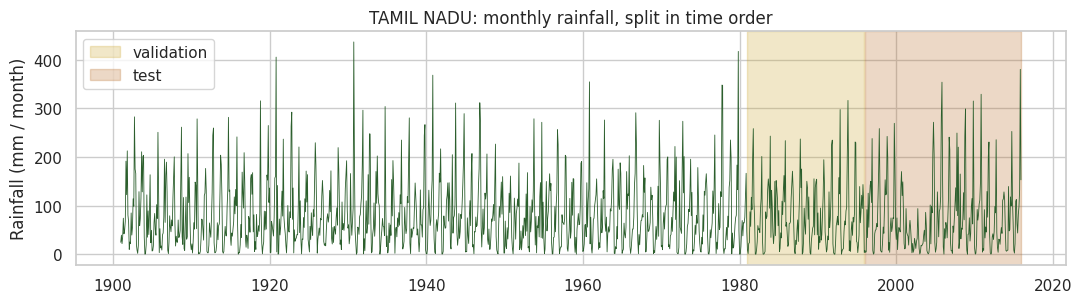

In [6]:
RAIN_FILE = 'rainfall in india 1901-2015.csv'
RAIN_URL = 'https://raw.githubusercontent.com/ranjith123620/Rainfall_Analysis_India_1901_2015/main/rainfall%20in%20india%201901-2015.csv'
SUBDIVISION = 'TAMIL NADU'
VAL_START, TEST_START = 1981, 1996
MONTHS = ['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']

rain_raw = pd.read_csv(RAIN_FILE) if os.path.exists(RAIN_FILE) else pd.read_csv(RAIN_URL)
sub = rain_raw[rain_raw.SUBDIVISION == SUBDIVISION].sort_values('YEAR')
series = pd.Series(sub[MONTHS].to_numpy(float).ravel(), name='rain_mm',
                   index=pd.date_range(f'{int(sub.YEAR.min())}-01-01', periods=len(sub) * 12, freq='MS'))
assert series.isna().sum() == 0, 'missing months in this sub-division'

year_of = series.index.year.to_numpy()
month_of = series.index.month.to_numpy() - 1                      # 0 = January ... 11 = December
NM = len(series)
y_mm = series.to_numpy()
y_log = np.log1p(y_mm)                                              # log1p tames the skew and the zero-rain months
i_val = int(np.argmax(year_of >= VAL_START))
i_test = int(np.argmax(year_of >= TEST_START))
val_idx, test_idx = np.arange(i_val, i_test), np.arange(i_test, NM)

print(f'{SUBDIVISION}: {NM} months | train {i_val} (1901-{VAL_START - 1}) | validation {i_test - i_val} '
      f'({VAL_START}-{TEST_START - 1}) | test {NM - i_test} ({TEST_START}-{year_of[-1]})')
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(series.index, y_mm, color=PAL[0], lw=0.6)
ax.axvspan(series.index[i_val], series.index[i_test - 1], color=PAL[2], alpha=0.25, label='validation')
ax.axvspan(series.index[i_test], series.index[-1], color=PAL[3], alpha=0.25, label='test')
ax.set(ylabel='Rainfall (mm / month)', title=f'{SUBDIVISION}: monthly rainfall, split in time order')
ax.legend(loc='upper left'); fig.tight_layout(); plt.show()

---
# 3. Unit 3: Clustering soil tests into fertiliser zones
**Project goal.** Group the 880 soil tests by their N, P and K so that each group (zone) can receive one fertiliser recommendation, without using the fertility label.

| Section | Algorithm | Why it fits this goal | What is tuned (child runs) |
|---|---|---|---|
| 3.1 | **K-means** | Compact zones, each described by one average N-P-K profile | number of clusters k (2-8) |
| 3.2 | **Hierarchical clustering** | Shows how soils merge into zones step by step (dendrogram); no assumption about cluster shape | linkage x dissimilarity |
| 3.3 | **Gaussian mixture model, fitted by EM** | Soft zones: every soil gets a probability of belonging to each zone | covariance type |
| **3.4** | **Comparison and selection** | The three algorithms compared on one score | - |

**Scores.** The **adjusted Rand index (ARI)** compares the clusters with the hidden fertility label (1 = identical grouping, 0 = chance) and is the score used to choose. Silhouette (higher is better), Davies-Bouldin (lower is better) and Calinski-Harabasz (higher is better) judge the clusters from the data alone. k = 3 wherever the number of zones must be fixed, matching the three fertility classes.

In [7]:
# ------------------------------------------------------------------
# Unit 3 shared code: experiment, scoring function, result store
# ------------------------------------------------------------------
mlflow.set_experiment(EXP3)
U3 = {}            # best setting of each algorithm -> compared in 3.4


def clustering_scores(labels):
    """All clustering scores in the standardised N-P-K space."""
    labels = np.asarray(labels)
    return {'ari_vs_hidden_label': adjusted_rand_score(hidden, labels),
            'silhouette': silhouette_score(Z, labels),
            'davies_bouldin': davies_bouldin_score(Z, labels),
            'calinski_harabasz': calinski_harabasz_score(Z, labels),
            'n_clusters_found': len(set(labels))}


def cluster_sizes(labels):
    return str(sorted(np.bincount(np.asarray(labels) - np.min(labels)).tolist(), reverse=True))

### 3.1 K-means
**What it does.** Places k centres, assigns every soil test to its nearest centre, moves each centre to the mean of its soil tests, and repeats. This minimises the within-cluster sum of squares (inertia). Because it can stop at a poor local minimum, 20 random starts are used for each k.

**What is tuned.** k = 2 to 8, one child run each. The k with the highest ARI is kept.

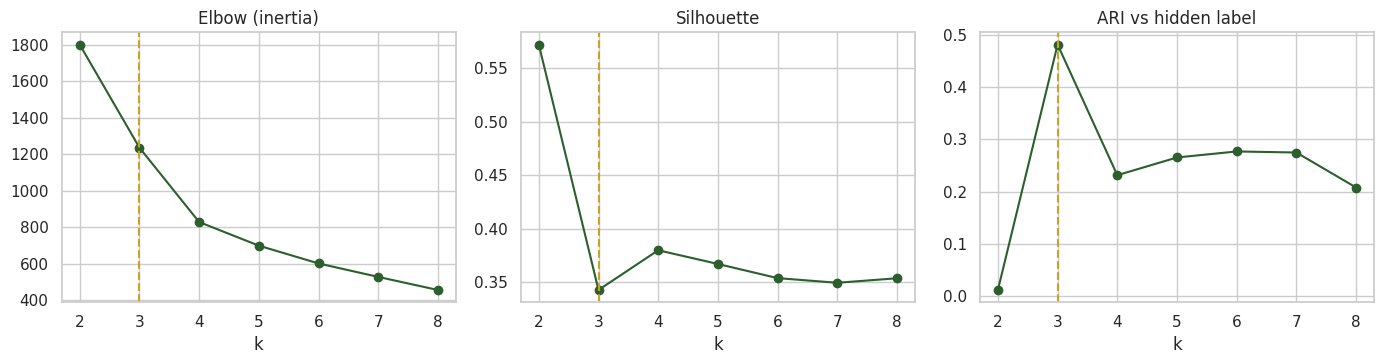

,k,ari_vs_hidden_label,silhouette,davies_bouldin,calinski_harabasz,n_clusters_found,inertia
0,2,0.012,0.572,0.762,408.646,2,1801.521
1,3,0.481,0.343,1.023,498.098,3,1236.005
2,4,0.231,0.380,0.812,639.257,4,827.784
3,5,0.265,0.367,0.865,608.445,5,698.143
4,6,0.277,0.354,0.880,593.613,6,600.552
5,7,0.275,0.349,0.956,583.803,7,526.695
6,8,0.208,0.354,0.902,598.366,8,454.906


In [8]:
# ==================================================================
# 3.1 K-means
# ==================================================================
rows = []
with mlflow.start_run(run_name='3.1 K-means') as run:

    # Step 1: one child run per number of clusters k
    for k in range(2, 9):
        km_k = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
        scores = {**clustering_scores(km_k.labels_), 'inertia': km_k.inertia_}
        child(f'k = {k}', {'k': k, 'cluster_sizes': cluster_sizes(km_k.labels_)}, scores)
        rows.append({'k': k, **scores})
    kmeans_tab = pd.DataFrame(rows)

    # Step 2: keep the k with the highest ARI and refit
    k_best = int(kmeans_tab.loc[kmeans_tab.ari_vs_hidden_label.idxmax(), 'k'])
    kmeans = KMeans(n_clusters=k_best, n_init=20, random_state=SEED).fit(Z)
    scores = clustering_scores(kmeans.labels_)

    # Step 3: log the parent run
    mlflow.set_tags({'level': 'parent', 'unit': '3', 'algorithm': 'K-means'})
    mlflow.log_params({**SOIL_PARAMS, 'algorithm': 'K-means', 'k_tried': '2-8', 'n_init': 20,
                       'best_k': k_best, 'chosen_by': 'highest ARI against the hidden label'})
    mlflow.log_metrics({**scores, 'inertia': kmeans.inertia_})
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
    for a, col, title in zip(ax, ['inertia', 'silhouette', 'ari_vs_hidden_label'],
                             ['Elbow (inertia)', 'Silhouette', 'ARI vs hidden label']):
        a.plot(kmeans_tab.k, kmeans_tab[col], 'o-', color=PAL[0])
        a.axvline(k_best, color=PAL[2], ls='--')
        a.set(xlabel='k', title=title)
    fig.tight_layout(); mlflow.log_figure(fig, 'choosing_k.png'); plt.show()
    info = log_sk(kmeans, Z[:3])

U3['K-means'] = {'setting': f'k = {k_best}', **scores, 'labels': kmeans.labels_, 'run_id': run.info.run_id}
kmeans_tab.round(3)

### 3.2 Hierarchical (agglomerative) clustering
**What it does.** Starts with every soil test as its own cluster and repeatedly merges the two closest clusters, building a tree (dendrogram) that is cut at 3 zones.
- The **dissimilarity** measures how different two soil tests are: Euclidean (straight-line), Manhattan (sum of differences), Chebyshev (largest single difference) or cosine (shape of the N-P-K profile, ignoring its size).
- The **linkage** defines the distance between two clusters: single (closest pair), complete (farthest pair), average (mean of all pairs) or Ward (smallest increase in variance; Euclidean only).

**What is tuned.** Every linkage x dissimilarity combination (13 child runs). The combination with the highest ARI is kept. The cophenetic correlation shows how faithfully each tree keeps the original dissimilarities.

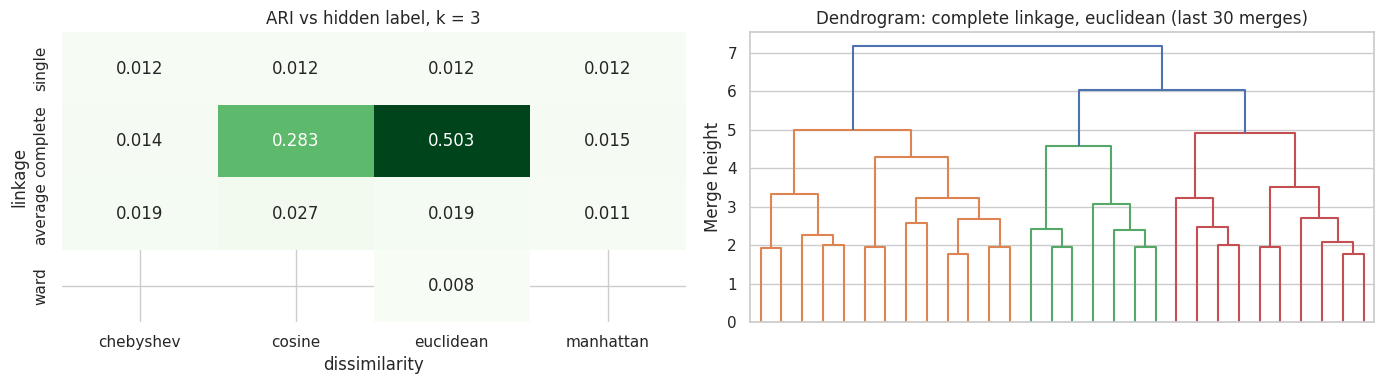

,linkage,dissimilarity,ari_vs_hidden_label,silhouette,davies_bouldin,calinski_harabasz,n_clusters_found,cophenetic_correlation,cluster_sizes
0,single,euclidean,0.012,0.547,0.713,206.231,3,0.730,"[813, 66, 1]"
1,single,manhattan,0.012,0.547,0.713,206.231,3,0.756,"[813, 66, 1]"
2,single,chebyshev,0.012,0.547,0.713,206.231,3,0.703,"[813, 66, 1]"
3,single,cosine,0.012,-0.253,11.886,204.095,3,0.178,"[811, 67, 2]"
4,complete,euclidean,0.503,0.337,1.051,486.743,3,0.675,"[458, 355, 67]"
5,complete,manhattan,0.015,0.347,1.015,397.767,3,0.759,"[664, 149, 67]"
6,complete,chebyshev,0.014,0.568,0.742,373.093,2,0.600,"[819, 61]"
7,complete,cosine,0.283,0.244,1.448,230.510,3,0.646,"[376, 319, 185]"
8,average,euclidean,0.019,0.393,0.799,333.869,3,0.830,"[759, 67, 54]"
9,average,manhattan,0.011,0.537,0.907,231.560,3,0.832,"[813, 44, 23]"


In [9]:
# ==================================================================
# 3.2 Hierarchical (agglomerative) clustering
# ==================================================================
DISSIMILARITIES = {'euclidean': 'euclidean', 'manhattan': 'cityblock', 'chebyshev': 'chebyshev', 'cosine': 'cosine'}
LINKAGES = ['single', 'complete', 'average', 'ward']
D = {name: pdist(Z, metric) for name, metric in DISSIMILARITIES.items()}       # pairwise dissimilarities

rows, trees = [], {}
with mlflow.start_run(run_name='3.2 Hierarchical clustering') as run:

    # Step 1: one child run per linkage x dissimilarity (Ward needs Euclidean)
    for link in LINKAGES:
        for dname in DISSIMILARITIES:
            if link == 'ward' and dname != 'euclidean':
                continue
            tree = linkage(Z, method='ward') if link == 'ward' else linkage(D[dname], method=link)
            labels = fcluster(tree, 3, criterion='maxclust')
            scores = {**clustering_scores(labels), 'cophenetic_correlation': cophenet(tree, D[dname])[0]}
            child(f'{link} linkage, {dname}', {'linkage': link, 'dissimilarity': dname,
                                                'cluster_sizes': cluster_sizes(labels)}, scores)
            rows.append({'linkage': link, 'dissimilarity': dname, **scores, 'cluster_sizes': cluster_sizes(labels)})
            trees[(link, dname)] = (tree, labels)
    hier_tab = pd.DataFrame(rows)

    # Step 2: keep the combination with the highest ARI (silhouette breaks ties)
    best = hier_tab.sort_values(['ari_vs_hidden_label', 'silhouette'], ascending=False).iloc[0]
    tree_best, labels_hier = trees[(best.linkage, best.dissimilarity)]
    scores = clustering_scores(labels_hier)

    # Step 3: log the parent run
    mlflow.set_tags({'level': 'parent', 'unit': '3', 'algorithm': 'Hierarchical clustering'})
    mlflow.log_params({**SOIL_PARAMS, 'algorithm': 'Agglomerative hierarchical clustering', 'k': 3,
                       'linkages_tried': ', '.join(LINKAGES), 'dissimilarities_tried': ', '.join(DISSIMILARITIES),
                       'best_linkage': best.linkage, 'best_dissimilarity': best.dissimilarity,
                       'chosen_by': 'highest ARI against the hidden label'})
    mlflow.log_metrics({**scores, 'cophenetic_correlation': best.cophenetic_correlation})
    mlflow.log_table(hier_tab.astype(str), 'linkage_x_dissimilarity.json')
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    sns.heatmap(hier_tab.pivot(index='linkage', columns='dissimilarity', values='ari_vs_hidden_label').reindex(LINKAGES),
                annot=True, fmt='.3f', cmap='Greens', cbar=False, ax=ax[0])
    ax[0].set_title('ARI vs hidden label, k = 3')
    dendrogram(tree_best, truncate_mode='lastp', p=30, color_threshold=tree_best[-2, 2], no_labels=True, ax=ax[1])
    ax[1].set(title=f'Dendrogram: {best.linkage} linkage, {best.dissimilarity} (last 30 merges)', ylabel='Merge height')
    fig.tight_layout(); mlflow.log_figure(fig, 'hierarchical_comparison.png'); plt.show()

U3['Hierarchical clustering'] = {'setting': f'{best.linkage} linkage, {best.dissimilarity}', **scores,
                                 'labels': labels_hier, 'run_id': run.info.run_id}
hier_tab.round(3)

### 3.3 Gaussian mixture model, fitted by EM
**What it does.** Treats each zone as a Gaussian cloud with its own centre and shape and gives every soil test a *probability* of belonging to each zone (soft clustering). The parameters are fitted by the **EM algorithm**: the E-step computes each soil test's zone probabilities, the M-step re-estimates the centres, shapes and weights from them; the log-likelihood never decreases.

**What is tuned.** The covariance type (zone shape): full (any ellipse), tied (one shared ellipse), diag (axis-aligned ellipses) or spherical (circles), with 3 components and 5 random starts each (4 child runs). The type with the highest ARI is kept, and its EM log-likelihood is logged at every iteration as an MLflow step metric.

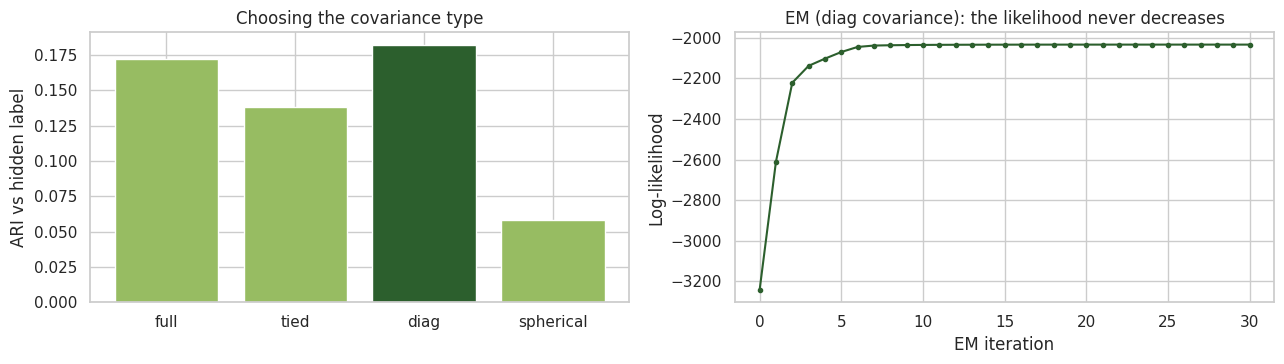

,covariance_type,ari_vs_hidden_label,silhouette,davies_bouldin,calinski_harabasz,n_clusters_found,bic,log_likelihood,em_iterations
0,full,0.172,0.169,1.487,315.766,3,4247.589,-2025.486,15
1,tied,0.138,0.331,0.976,438.629,3,5424.316,-2654.529,10
2,diag,0.182,0.132,1.648,286.315,3,4202.850,-2033.626,13
3,spherical,0.058,0.345,0.940,464.789,3,6819.178,-3362.129,8


In [10]:
# ==================================================================
# 3.3 Gaussian mixture model (EM)
# ==================================================================
COV_TYPES = ['full', 'tied', 'diag', 'spherical']
rows, gmm_labels = [], {}
with mlflow.start_run(run_name='3.3 Gaussian mixture model (EM)') as run:

    # Step 1: one child run per covariance type
    for ct in COV_TYPES:
        gm = GaussianMixture(n_components=3, covariance_type=ct, n_init=5, random_state=SEED).fit(Z)
        labels = gm.predict(Z)
        scores = {**clustering_scores(labels), 'bic': gm.bic(Z), 'log_likelihood': gm.score(Z) * len(Z),
                  'em_iterations': gm.n_iter_}
        child(f'covariance = {ct}', {'covariance_type': ct, 'n_components': 3,
                                     'cluster_sizes': cluster_sizes(labels)}, scores)
        rows.append({'covariance_type': ct, **scores})
        gmm_labels[ct] = labels
    gmm_tab = pd.DataFrame(rows)

    # Step 2: keep the covariance type with the highest ARI
    best_ct = gmm_tab.sort_values(['ari_vs_hidden_label', 'silhouette'], ascending=False).iloc[0].covariance_type
    scores = clustering_scores(gmm_labels[best_ct])

    # Step 3: rerun EM one iteration at a time to record the log-likelihood (MLflow step metric)
    em = GaussianMixture(n_components=3, covariance_type=best_ct, max_iter=1, warm_start=True, random_state=SEED)
    em_path = []
    for it in range(200):
        em.fit(Z)
        em_path.append(em.score(Z) * len(Z))
        mlflow.log_metric('em_log_likelihood', em_path[-1], step=it)
        if it > 0 and abs(em_path[-1] - em_path[-2]) < 1e-3:
            break

    # Step 4: log the parent run
    mlflow.set_tags({'level': 'parent', 'unit': '3', 'algorithm': 'Gaussian mixture model (EM)'})
    mlflow.log_params({**SOIL_PARAMS, 'algorithm': 'Gaussian mixture model fitted by EM', 'n_components': 3, 'n_init': 5,
                       'covariance_types_tried': ', '.join(COV_TYPES), 'best_covariance_type': best_ct,
                       'chosen_by': 'highest ARI against the hidden label'})
    mlflow.log_metrics({**scores, 'em_iterations_logged': len(em_path),
                        'em_never_decreased': float(np.all(np.diff(em_path) >= -1e-6))})
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
    ax[0].bar(gmm_tab.covariance_type, gmm_tab.ari_vs_hidden_label, color=[PAL[0] if c == best_ct else PAL[1] for c in gmm_tab.covariance_type])
    ax[0].set(ylabel='ARI vs hidden label', title='Choosing the covariance type')
    ax[1].plot(em_path, 'o-', color=PAL[0], ms=3)
    ax[1].set(xlabel='EM iteration', ylabel='Log-likelihood', title=f'EM ({best_ct} covariance): the likelihood never decreases')
    fig.tight_layout(); mlflow.log_figure(fig, 'gmm_comparison_and_em.png'); plt.show()

U3['Gaussian mixture model (EM)'] = {'setting': f'{best_ct} covariance, 3 components', **scores,
                                     'labels': gmm_labels[best_ct], 'run_id': run.info.run_id}
gmm_tab.round(3)

### 3.4 Comparison and selection: best clustering algorithm
The best setting of each of the three algorithms is compared on the same score, **ARI against the hidden fertility label** (silhouette breaks ties). The chosen clusters become the **fertiliser zones**.

A hierarchical tree cannot place a *new* soil test, so the chosen zones are made usable with a **nearest-centroid rule**: a new soil test joins the zone with the closest average N-P-K profile. That rule is registered as `soil-zone-clusterer`. Each zone is described with the Soil Health Card levels (Low / Medium / High).

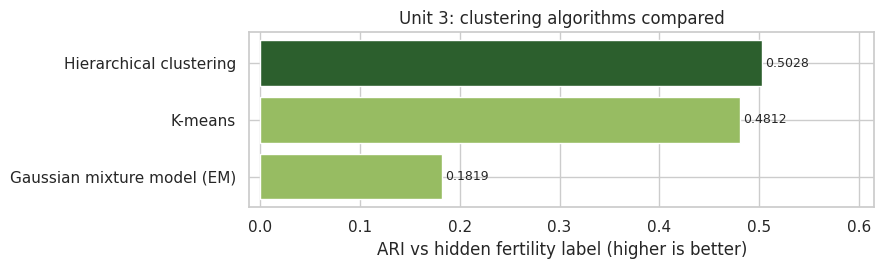

Registered soil-zone-clusterer version 1 -> alias "champion"
CHOSEN: Hierarchical clustering (complete linkage, euclidean), ARI 0.503 | runner-up: K-means (0.481)
Nearest-centroid rule reproduces 96.0 % of the zones


Successfully registered model 'soil-zone-clusterer'.
Created version '1' of model 'soil-zone-clusterer'.


,N,P,K,N level,P level,K level,soil tests
zone,,,,,,,
1,231.0,87.2,526.0,Low,High,High,67
2,303.5,9.3,505.2,Medium,Low,High,458
3,176.7,7.4,488.9,Low,Low,High,355


,algorithm,best setting,ari_vs_hidden_label,silhouette,davies_bouldin,calinski_harabasz,n_clusters_found
0,Hierarchical clustering,"complete linkage, euclidean",0.503,0.337,1.051,486.743,3
1,K-means,k = 3,0.481,0.343,1.023,498.098,3
2,Gaussian mixture model (EM),"diag covariance, 3 components",0.182,0.132,1.648,286.315,3


In [11]:
# ==================================================================
# 3.4 Comparison and selection (Unit 3)
# ==================================================================
SCORE_COLS = ['ari_vs_hidden_label', 'silhouette', 'davies_bouldin', 'calinski_harabasz', 'n_clusters_found']
comp3 = (pd.DataFrame([{'algorithm': a, 'best setting': r['setting'], **{c: r[c] for c in SCORE_COLS}} for a, r in U3.items()])
           .sort_values(['ari_vs_hidden_label', 'silhouette'], ascending=False).reset_index(drop=True))
chosen3, runner3 = comp3.iloc[0], comp3.iloc[1]
zones = U3[chosen3.algorithm]['labels']

with mlflow.start_run(run_name='3.4 Comparison and selection: best clustering algorithm') as run:
    mlflow.set_tags({'level': 'selection', 'unit': '3'})
    mlflow.log_params({'algorithms_compared': ', '.join(comp3.algorithm),
                       'selection_rule': 'highest ARI against the hidden fertility label; ties broken by silhouette',
                       'chosen_algorithm': chosen3.algorithm, 'chosen_setting': chosen3['best setting'],
                       'runner_up': runner3.algorithm})
    mlflow.log_metrics({**{f'ari_{slug(a)}': v for a, v in zip(comp3.algorithm, comp3.ari_vs_hidden_label)},
                        **{f'silhouette_{slug(a)}': v for a, v in zip(comp3.algorithm, comp3.silhouette)},
                        'chosen_ari': chosen3.ari_vs_hidden_label})
    mlflow.log_table(comp3.astype(str), 'comparison.json')
    fig = comparison_chart(list(comp3.algorithm), list(comp3.ari_vs_hidden_label),
                           'Unit 3: clustering algorithms compared', 'ARI vs hidden fertility label (higher is better)')
    mlflow.log_figure(fig, 'comparison.png'); plt.show()

    # Fertiliser zones: average N, P, K of each zone (original units) and Soil Health Card level
    level = lambda v, lo, hi: 'Low' if v < lo else ('Medium' if v <= hi else 'High')
    profile = soil_c[['N', 'P', 'K']].assign(zone=zones).groupby('zone').mean().round(1)
    profile['N level'] = profile.N.apply(lambda v: level(v, 280, 560))
    profile['P level'] = profile.P.apply(lambda v: level(v, 10, 25))
    profile['K level'] = profile.K.apply(lambda v: level(v, 108, 280))
    profile['soil tests'] = pd.Series(zones).value_counts().sort_index().values
    mlflow.log_table(profile.reset_index().astype(str), 'fertiliser_zones.json')

    # Deployable rule for new soil tests: nearest zone centre
    nc = NearestCentroid().fit(Z, zones)
    agreement = float(np.mean(nc.predict(Z) == zones) * 100)
    mlflow.log_metric('nearest_centroid_agreement_pct', agreement)
    info = log_sk(nc, Z[:3])

client.set_tag(U3[chosen3.algorithm]['run_id'], 'chosen', 'yes')
register(run.info.run_id, info.model_uri if info else None, 'soil-zone-clusterer', 'champion',
         f'{chosen3.algorithm} ({chosen3["best setting"]}) on standardised N, P, K, served by a nearest-centroid rule; ARI {chosen3.ari_vs_hidden_label:.3f}.')
print(f'CHOSEN: {chosen3.algorithm} ({chosen3["best setting"]}), ARI {chosen3.ari_vs_hidden_label:.3f}'
      f' | runner-up: {runner3.algorithm} ({runner3.ari_vs_hidden_label:.3f})')
print(f'Nearest-centroid rule reproduces {agreement:.1f} % of the zones')
display(profile)
comp3.round(3)

---
# 4. Unit 4: Forecasting next month's rainfall as a sequence
**Project goal.** Give each field a rainfall outlook: the probability that next month will be *Scanty, Deficient, Normal or Excess* (IMD departure-from-normal scale), from the months seen so far.

| Section | Algorithm | Why it fits this goal | What is tuned (child runs) |
|---|---|---|---|
| 4.1 | **Markov chain** | The simplest sequence model: next month's category depends on the last one(s) | order x seasonal tables |
| 4.2 | **Hidden Markov model, Baum-Welch** | Hidden wet/dry regimes drive the rainfall; trained by EM (forward-backward) | number of hidden states |
| 4.3 | **Hidden Markov model, Viterbi training** | Same model, trained by hard EM on the single most likely regime path | number of hidden states |
| 4.4 | **Kalman filter (linear dynamical system)** | A continuous hidden state instead of discrete regimes | size of the hidden state |
| **4.5** | **Comparison and selection** | The four algorithms compared on one score | - |

**Score.** Every algorithm forecasts category probabilities one month ahead and is scored by the **log-loss** on the validation years 1981-1995 (lower is better; it rewards honest probabilities). Settings are chosen on validation, then the model is refitted on 1901-1995 and the test years 1996-2015 are reported. **Monthly climatology** (the usual category for that month) is logged as a baseline that a useful sequence model should beat.

### 4.0 Shared code: monthly normals, rainfall categories, scoring, and the tuning routine

In [12]:
# ------------------------------------------------------------------
# Unit 4 shared code
# ------------------------------------------------------------------
mlflow.set_experiment(EXP4)
CATS = ['Scanty', 'Deficient', 'Normal', 'Excess']
DEP_EDGES = np.array([-60., -20., 20.])        # Scanty < -60 % <= Deficient < -20 % <= Normal < +20 % <= Excess
NC = len(CATS)


def make_climate(fit_end):
    """Monthly normals computed only from months before index fit_end (nothing leaks from later years)."""
    c = {}
    c['mm'] = np.array([y_mm[:fit_end][month_of[:fit_end] == m].mean() for m in range(12)])
    c['mu_log'] = np.array([y_log[:fit_end][month_of[:fit_end] == m].mean() for m in range(12)])
    c['sd_log'] = np.array([y_log[:fit_end][month_of[:fit_end] == m].std() for m in range(12)])
    c['dep'] = (y_mm - c['mm'][month_of]) / c['mm'][month_of] * 100              # % departure from the month's normal
    c['state'] = np.searchsorted(DEP_EDGES, c['dep'], side='right')               # 0 Scanty ... 3 Excess
    c['edges_log'] = np.log1p(c['mm'][:, None] * (1 + DEP_EDGES[None, :] / 100))  # category borders in log1p units
    c['dep_mean_state'] = np.array([c['dep'][:fit_end][c['state'][:fit_end] == s].mean() for s in range(NC)])
    return c


def anomalies(c):
    """Standardised anomaly: (log1p rain - this month's normal) / this month's spread. Removes the seasonal cycle."""
    return (y_log - c['mu_log'][month_of]) / c['sd_log'][month_of]


def category_probs(w, mu, sd, edges_log):
    """P(each category) when next month's log1p-rainfall ~ sum_j w_j * Normal(mu_j, sd_j)."""
    cdf = norm.cdf((edges_log[None, :] - mu[:, None]) / sd[:, None])
    cdf = np.hstack([np.zeros((len(w), 1)), cdf, np.ones((len(w), 1))])
    return np.clip(w @ np.diff(cdf, axis=1), 1e-6, 1)


def score(idx, point_mm, probs, c):
    """Common scoreboard: category log-loss (used to choose), accuracy, macro-F1, and the error in mm."""
    true_s = c['state'][idx]
    pred_s = probs.argmax(1)
    return {'cat_log_loss': float(-np.mean(np.log(probs[np.arange(len(idx)), true_s] / probs.sum(1)))),
            'cat_accuracy': float(np.mean(pred_s == true_s) * 100),
            'cat_macro_f1': float(f1_score(true_s, pred_s, average='macro', labels=range(NC)) * 100),
            'rmse_mm': float(np.sqrt(np.mean((point_mm - y_mm[idx]) ** 2))),
            'mae_mm': float(np.mean(np.abs(point_mm - y_mm[idx])))}


def category_to_mm(probs, idx, c):
    """Category probabilities -> millimetres: normal x (1 + expected % departure)."""
    return c['mm'][month_of[idx]] * (1 + (probs @ c['dep_mean_state']) / 100)


c_val = make_climate(i_val)      # normals from 1901-1980: used while choosing settings
c_all = make_climate(i_test)     # normals from 1901-1995: used for the final refit and the test years
TS_PARAMS = {'dataset': 'IMD monthly rainfall 1901-2015', 'subdivision': SUBDIVISION, 'months': NM,
             'split': f'train 1901-{VAL_START - 1} | validation {VAL_START}-{TEST_START - 1} | test {TEST_START}-{year_of[-1]}',
             'forecast': 'next month, category probabilities'}
U4 = {}          # best setting of each algorithm -> compared in 4.5


def tune_algorithm(name, settings, fit_forecast, make_figures):
    """Same procedure for every Unit 4 algorithm.
    1. One child run per setting: fit on 1901-1980, score on 1981-1995.
    2. Keep the setting with the lowest validation log-loss.
    3. Refit it on 1901-1995, score the test years 1996-2015, log charts and the model in the parent run.
    fit_forecast(setting, climate, fit_end, idx) must return dict(pt=mm forecast, probs=category probs, model=..., extra={...})."""
    with mlflow.start_run(run_name=name) as run:
        rows = []
        for st in settings:
            r = fit_forecast(st, c_val, i_val, val_idx)
            sc = score(val_idx, r['pt'], r['probs'], c_val)
            child(', '.join(f'{k} = {v}' for k, v in st.items()), st, {**{f'val_{k}': v for k, v in sc.items()}, **r['extra']})
            rows.append({**st, **sc, **r['extra']})
        tab = pd.DataFrame(rows)
        best_i = int(tab.cat_log_loss.idxmin())
        best = settings[best_i]

        r = fit_forecast(best, c_all, i_test, test_idx)
        test = score(test_idx, r['pt'], r['probs'], c_all)
        mlflow.set_tags({'level': 'parent', 'unit': '4', 'algorithm': name.split(' ', 1)[1]})
        mlflow.log_params({**TS_PARAMS, 'algorithm': name.split(' ', 1)[1], 'settings_tried': str(settings),
                           **{f'best_{k}': v for k, v in best.items()}, 'chosen_by': 'lowest validation log-loss'})
        mlflow.log_metrics({**{f'val_{k}': float(tab.loc[best_i, k]) for k in ['cat_log_loss', 'cat_accuracy', 'cat_macro_f1', 'rmse_mm']},
                            **{f'test_{k}': v for k, v in test.items()}, **r['extra']})
        mlflow.log_table(tab.astype(str), 'settings_results.json')
        for fname, fig in make_figures(best, r, tab).items():
            mlflow.log_figure(fig, fname); plt.show()
        info = log_sk(r['model'])
    U4[name.split(' ', 1)[1]] = {'setting': ', '.join(f'{k} = {v}' for k, v in best.items()),
                                 'val_log_loss': float(tab.loc[best_i, 'cat_log_loss']),
                                 **{f'test_{k}': v for k, v in test.items()},
                                 'run_id': run.info.run_id, 'model_uri': info.model_uri if info else None}
    print(f'{name}: best {U4[name.split(" ", 1)[1]]["setting"]} | validation log-loss {tab.loc[best_i, "cat_log_loss"]:.4f}'
          f' | test log-loss {test["cat_log_loss"]:.4f}')
    return tab


def states_figure(tab, title):
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ax.plot(tab.n_states, tab.cat_log_loss, 'o-', color=PAL[0])
    ax.set(xlabel='Hidden states', ylabel='Validation log-loss', title=title)
    ax.ticklabel_format(axis='y', useOffset=False); ax.set_xticks(tab.n_states)
    fig.tight_layout()
    return fig


# Baseline (not one of the compared algorithms): monthly climatology
def climatology(c, fit_end, idx):
    freq = np.array([[np.mean(c['state'][:fit_end][month_of[:fit_end] == m] == s) for s in range(NC)] for m in range(12)])
    return c['mm'][month_of[idx]], np.clip(freq[month_of[idx]], 1e-3, 1)

with mlflow.start_run(run_name='4.0 Baseline: monthly climatology') as run:
    s_val = score(val_idx, *climatology(c_val, i_val, val_idx), c_val)
    s_test = score(test_idx, *climatology(c_all, i_test, test_idx), c_all)
    mlflow.set_tags({'level': 'baseline', 'unit': '4', 'algorithm': 'Monthly climatology'})
    mlflow.log_params({**TS_PARAMS, 'algorithm': 'Monthly climatology (baseline)'})
    mlflow.log_metrics({**{f'val_{k}': v for k, v in s_val.items()}, **{f'test_{k}': v for k, v in s_test.items()}})
BASELINE4 = {'setting': 'none', 'val_log_loss': s_val['cat_log_loss'], **{f'test_{k}': v for k, v in s_test.items()}}
print(f'Baseline (climatology): validation log-loss {s_val["cat_log_loss"]:.4f} | test log-loss {s_test["cat_log_loss"]:.4f}')

Baseline (climatology): validation log-loss 1.3003 | test log-loss 1.2929


### 4.1 Markov chain
**What it does.** The rainfall category of the next month depends only on the category of the last month(s): P(next | current). The transition probabilities are counted from the training years (with +1 smoothing).

**What is tuned.** `order` = how many past months are remembered (0, 1 or 2) and `seasons` = how many transition tables per year (1, one per IMD season, or one per month): 9 child runs. Order 0 against order 1 shows directly whether last month's category helps.

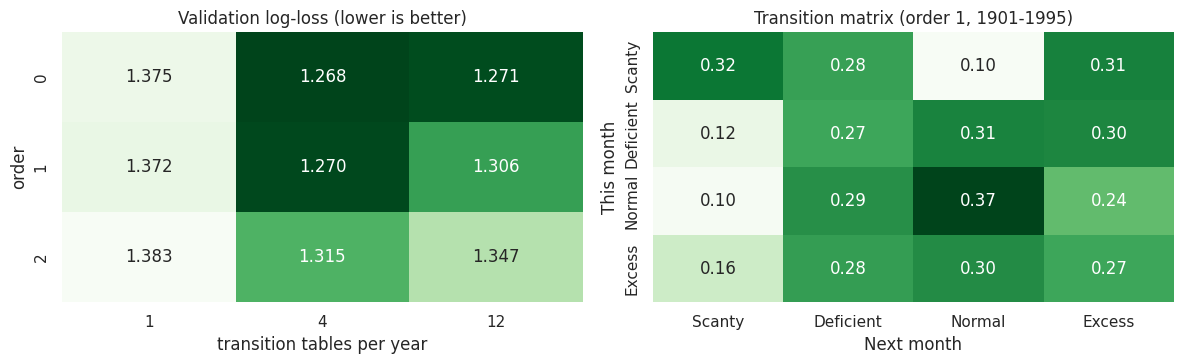

4.1 Markov chain: best order = 0, seasons = 4 | validation log-loss 1.2680 | test log-loss 1.3142


,order,seasons,cat_log_loss,cat_accuracy,cat_macro_f1,rmse_mm,mae_mm,n_params
0,0,1,1.3748,26.6667,10.5263,42.1799,31.6947,3
1,0,4,1.2680,38.3333,40.1813,42.4674,31.5942,12
2,0,12,1.2708,38.3333,36.7027,43.2079,31.8585,36
3,1,1,1.3724,26.6667,20.1102,41.8281,31.4414,12
4,1,4,1.2695,40.0000,39.5660,41.8802,31.1344,48
5,1,12,1.3060,38.3333,37.4475,42.7385,31.1544,144
6,2,1,1.3833,28.8889,24.2604,41.5231,31.1711,48
7,2,4,1.3150,33.3333,33.6876,41.7004,31.0499,192
8,2,12,1.3473,32.7778,32.6963,44.7971,32.6432,576


In [13]:
# ==================================================================
# 4.1 Markov chain
# ==================================================================
SEASON_OF_MONTH = {1: [0] * 12,                                  # one table all year
                   4: [0, 0, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3],      # IMD seasons: Jan-Feb | Mar-May | Jun-Sep | Oct-Dec
                   12: list(range(12))}                          # one table per month


class MarkovChain:
    """Markov chain over the 4 rainfall categories."""

    def __init__(self, order=1, seasons=1, alpha=1.0):
        self.order, self.seasons, self.alpha = order, seasons, alpha
        self.group = np.array(SEASON_OF_MONTH[seasons])

    def _context(self, s, t):
        """(season of month t, previous `order` categories) encoded as one row index of the transition table."""
        return self.group[month_of[t]] * NC ** self.order + sum(int(s[t - 1 - j]) * NC ** j for j in range(self.order))

    def fit(self, s, t_end):
        counts = np.zeros((self.seasons * NC ** self.order, NC))
        for t in range(self.order, t_end):
            counts[self._context(s, t), s[t]] += 1
        self.P = (counts + self.alpha) / (counts + self.alpha).sum(1, keepdims=True)   # smoothed transition probabilities
        return self

    def predict_proba(self, s, idx):
        return np.array([self.P[self._context(s, t)] for t in idx])

    @property
    def n_params(self):
        return self.seasons * NC ** self.order * (NC - 1)


def fit_forecast_markov(st, c, fit_end, idx):
    s = c['state']
    mc = MarkovChain(st['order'], st['seasons']).fit(s, fit_end)
    probs = mc.predict_proba(s, idx)
    return dict(pt=category_to_mm(probs, idx, c), probs=probs, model=mc, extra={'n_params': mc.n_params})


def figures_markov(best, r, tab):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    grid = tab.pivot(index='order', columns='seasons', values='cat_log_loss')
    sns.heatmap(grid, annot=True, fmt='.3f', cmap='Greens_r', cbar=False, ax=ax[0])
    ax[0].set(title='Validation log-loss (lower is better)', xlabel='transition tables per year', ylabel='order')
    P = MarkovChain(1, 1).fit(c_all['state'], i_test).P
    sns.heatmap(P, annot=True, fmt='.2f', cmap='Greens', cbar=False, xticklabels=CATS, yticklabels=CATS, ax=ax[1])
    ax[1].set(title='Transition matrix (order 1, 1901-1995)', xlabel='Next month', ylabel='This month')
    fig.tight_layout()
    return {'markov_chain.png': fig}


markov_tab = tune_algorithm('4.1 Markov chain', [{'order': o, 'seasons': s} for o in (0, 1, 2) for s in (1, 4, 12)],
                            fit_forecast_markov, figures_markov)
markov_tab.round(4)

### 4.2 Hidden Markov model (Gaussian states), trained by Baum-Welch
**What it does.** A hidden regime (for example *dry* or *normal*) follows a Markov chain with start probabilities `pi` and transition matrix `A`; each regime produces the de-seasonalised rainfall anomaly from its own Gaussian (`mu`, `sd`). The class below contains the HMM algorithms:
- **Forward algorithm with scaling factors** (`forward`): the probability of each regime given the months so far, rescaled each month so it never underflows.
- **Forward-backward** (`forward_backward`): the probability of each regime given *all* months (`gamma`) and of each regime-to-regime move (`xi`).
- **Baum-Welch** (`fit`): EM for HMMs. E-step = forward-backward; M-step = re-estimate `pi`, `A`, `mu`, `sd`. 5 random starts, the best kept.
- **Viterbi** (`decode`): the single most likely sequence of regimes.

The forecast for next month uses the forward algorithm: the current belief about the regime, pushed one step through `A`.

**What is tuned.** The number of hidden states, 2 to 6 (5 child runs).

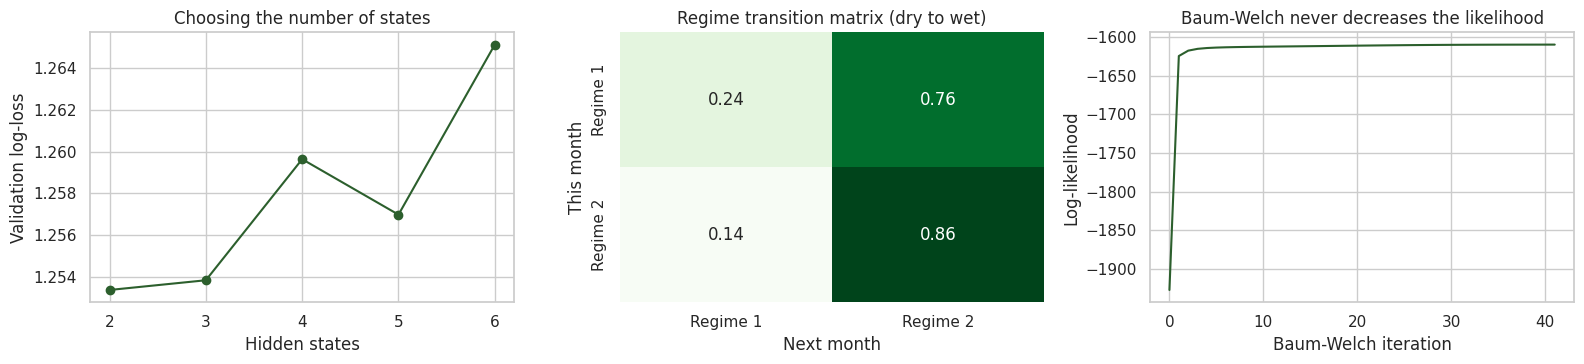

4.2 HMM (Baum-Welch): best n_states = 2 | validation log-loss 1.2534 | test log-loss 1.2772


,n_states,cat_log_loss,cat_accuracy,cat_macro_f1,rmse_mm,mae_mm,train_loglik,n_params,em_iterations
0,2,1.2534,39.4444,36.2518,42.3606,32.1778,-1352.9261,7,115
1,3,1.2539,36.1111,34.9729,42.0981,31.9718,-1349.1401,14,156
2,4,1.2596,35.5556,32.4285,42.2216,31.9945,-1343.0287,23,174
3,5,1.2570,36.1111,31.9084,42.0721,31.9862,-1338.8355,34,139
4,6,1.2651,36.6667,33.8310,42.4081,32.2755,-1331.1163,47,200


In [14]:
# ==================================================================
# 4.2 Hidden Markov model (Gaussian states), Baum-Welch
# ==================================================================
class GaussianHMM:
    """HMM with n hidden states, each emitting the monthly anomaly as one Gaussian number."""

    def __init__(self, n_states, seed=0):
        rng = np.random.RandomState(seed)
        self.n, self.seed = n_states, seed
        self.pi = np.full(n_states, 1 / n_states)
        A = 0.7 * np.eye(n_states) + 0.3 * rng.dirichlet(np.ones(n_states), n_states)
        self.A = A / A.sum(1, keepdims=True)

    def _emission(self, x):
        """b[t, j] = Normal(x_t; mu_j, sd_j)"""
        return np.maximum(norm.pdf(x[:, None], self.mu[None, :], self.sd[None, :]), 1e-300)

    def forward(self, x):
        """Forward algorithm with scaling: alpha[t] = P(state_t | x_1..x_t); log-likelihood = sum(log c)."""
        T, b = len(x), self._emission(x)
        alpha, c = np.zeros((T, self.n)), np.zeros(T)
        a = self.pi * b[0]; c[0] = a.sum(); alpha[0] = a / c[0]
        for t in range(1, T):
            a = (alpha[t - 1] @ self.A) * b[t]; c[t] = a.sum(); alpha[t] = a / c[t]
        return alpha, c, b

    def forward_backward(self, x):
        """E-step: gamma = P(state_t | all data), xi = expected number of i -> j moves."""
        alpha, c, b = self.forward(x)
        T = len(x); beta = np.ones((T, self.n))
        for t in range(T - 2, -1, -1):
            beta[t] = (self.A @ (b[t + 1] * beta[t + 1])) / c[t + 1]
        gamma = alpha * beta
        xi = self.A * (alpha[:-1].T @ (b[1:] * beta[1:] / c[1:, None]))
        return gamma, xi, float(np.log(c).sum())

    def fit(self, x, n_iter=200, tol=1e-2):
        """Baum-Welch (EM for HMMs); stops when the log-likelihood gains less than tol."""
        rng = np.random.RandomState(self.seed)
        self.mu = np.sort(rng.choice(x, self.n, replace=False)).astype(float)
        self.sd = np.full(self.n, x.std())
        self.ll_path = []
        for it in range(n_iter):
            gamma, xi, ll = self.forward_backward(x)              # E-step
            self.ll_path.append(ll)
            if it > 0 and ll - self.ll_path[-2] < tol:
                break
            self.pi = gamma[0] / gamma[0].sum()                   # M-step
            self.A = xi / xi.sum(1, keepdims=True)
            w = gamma.sum(0) + 1e-9
            self.mu = (gamma * x[:, None]).sum(0) / w
            self.sd = np.sqrt(np.maximum((gamma * (x[:, None] - self.mu) ** 2).sum(0) / w, 1e-3))
        self.train_ll = self.forward_backward(x)[2]
        return self

    def decode(self, x):
        """Viterbi algorithm: the single most likely path of hidden states."""
        T, lb, lA = len(x), np.log(self._emission(x)), np.log(self.A + 1e-300)
        delta = np.log(self.pi + 1e-300) + lb[0]
        back = np.zeros((T, self.n), int)
        for t in range(1, T):
            cand = delta[:, None] + lA
            back[t] = cand.argmax(0); delta = cand.max(0) + lb[t]
        path = np.zeros(T, int); path[-1] = delta.argmax()
        for t in range(T - 1, 0, -1):
            path[t - 1] = back[t, path[t]]
        return path

    @property
    def n_params(self):
        n = self.n
        return n * (n - 1) + (n - 1) + 2 * n


def hmm_forecast(m, z, c, upto, idx):
    """One-month-ahead forecasts: the regime belief at month t uses only the months before t."""
    alpha, _, _ = m.forward(z[:upto])
    belief = {0: m.pi, **{t: alpha[t - 1] @ m.A for t in range(1, upto)}}
    pt, probs = [], []
    for t in idx:
        mu = c['mu_log'][month_of[t]] + c['sd_log'][month_of[t]] * m.mu
        sd = c['sd_log'][month_of[t]] * m.sd
        pt.append((belief[t] * np.exp(mu + sd ** 2 / 2)).sum() - 1)          # back in millimetres
        probs.append(category_probs(belief[t], mu, sd, c['edges_log'][month_of[t]]))
    return np.array(pt), np.array(probs)


def fit_forecast_bw(st, c, fit_end, idx):
    z = anomalies(c)
    m = max((GaussianHMM(st['n_states'], seed=s).fit(z[:fit_end]) for s in range(5)), key=lambda h: h.train_ll)
    pt, probs = hmm_forecast(m, z, c, idx[-1] + 1, idx)
    return dict(pt=pt, probs=probs, model=m,
                extra={'train_loglik': m.train_ll, 'n_params': m.n_params, 'em_iterations': len(m.ll_path)})


def figures_bw(best, r, tab):
    m = r['model']; order = np.argsort(m.mu)
    names = [f'Regime {i + 1}' for i in range(m.n)]
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    ax[0].plot(tab.n_states, tab.cat_log_loss, 'o-', color=PAL[0])
    ax[0].set(xlabel='Hidden states', ylabel='Validation log-loss', title='Choosing the number of states')
    ax[0].ticklabel_format(axis='y', useOffset=False); ax[0].set_xticks(tab.n_states)
    sns.heatmap(m.A[np.ix_(order, order)], annot=True, fmt='.2f', cmap='Greens', cbar=False, xticklabels=names, yticklabels=names, ax=ax[1])
    ax[1].set(title='Regime transition matrix (dry to wet)', xlabel='Next month', ylabel='This month')
    ax[2].plot(m.ll_path, color=PAL[0])
    ax[2].set(xlabel='Baum-Welch iteration', ylabel='Log-likelihood', title='Baum-Welch never decreases the likelihood')
    fig.tight_layout()
    return {'hmm_baum_welch.png': fig}


bw_tab = tune_algorithm('4.2 HMM (Baum-Welch)', [{'n_states': n} for n in range(2, 7)], fit_forecast_bw, figures_bw)
bw_tab.round(4)

### 4.3 Hidden Markov model (Gaussian states), trained by Viterbi training
**What it does.** The same model as 4.2, trained by **hard EM**: every month is assigned to its single most likely regime (the Viterbi path), the parameters are re-estimated from those assignments by counting and averaging, and this repeats until the path stops changing. Baum-Welch (4.2) instead uses the *probability* of every regime for every month (soft EM). The forecast is made exactly as in 4.2.

**What is tuned.** The number of hidden states, 2 to 6 (5 child runs).

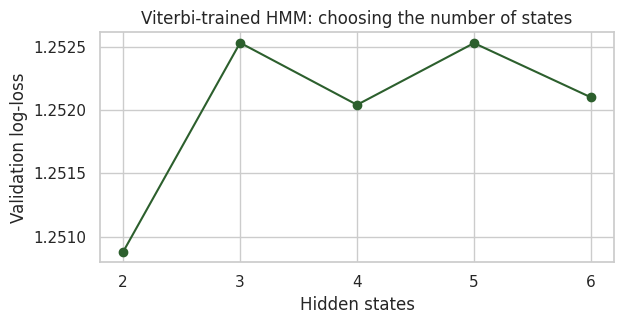

4.3 HMM (Viterbi training): best n_states = 2 | validation log-loss 1.2509 | test log-loss 1.2954


,n_states,cat_log_loss,cat_accuracy,cat_macro_f1,rmse_mm,mae_mm,train_loglik,n_params,em_iterations
0,2,1.2509,40.0,34.212,42.5572,32.5908,-1362.2756,7,7
1,3,1.2525,40.0,34.212,42.5741,32.6210,-1361.5347,14,5
2,4,1.2520,40.0,34.212,42.6012,32.6300,-1360.8987,23,4
3,5,1.2525,40.0,34.212,42.6335,32.6935,-1361.4254,34,3
4,6,1.2521,40.0,34.212,42.5781,32.6220,-1360.8381,47,3


In [15]:
# ==================================================================
# 4.3 Hidden Markov model (Gaussian states), Viterbi training
# ==================================================================
class ViterbiTrainedHMM(GaussianHMM):
    """Gaussian HMM from 4.2 with a different fit(): hard EM on the Viterbi path."""

    def fit(self, x, n_iter=100):
        rng = np.random.RandomState(self.seed)
        self.mu = np.sort(rng.choice(x, self.n, replace=False)).astype(float)
        self.sd = np.full(self.n, x.std())
        self.ll_path, path = [], None
        for it in range(n_iter):
            new_path = self.decode(x)                                        # hard E-step: most likely regimes
            self.ll_path.append(float(np.log(self.forward(x)[1]).sum()))
            if path is not None and np.array_equal(new_path, path):
                break
            path = new_path
            counts = np.ones((self.n, self.n))                               # M-step: count and average
            np.add.at(counts, (path[:-1], path[1:]), 1)
            self.A = counts / counts.sum(1, keepdims=True)
            self.pi = (np.bincount(path[:1], minlength=self.n) + 1.0) / (1 + self.n)
            for j in range(self.n):
                xj = x[path == j]
                if len(xj) > 1:
                    self.mu[j], self.sd[j] = xj.mean(), max(xj.std(), 0.03)
        self.train_ll = float(np.log(self.forward(x)[1]).sum())
        return self


def fit_forecast_viterbi(st, c, fit_end, idx):
    z = anomalies(c)
    m = max((ViterbiTrainedHMM(st['n_states'], seed=s).fit(z[:fit_end]) for s in range(5)), key=lambda h: h.train_ll)
    pt, probs = hmm_forecast(m, z, c, idx[-1] + 1, idx)
    return dict(pt=pt, probs=probs, model=m,
                extra={'train_loglik': m.train_ll, 'n_params': m.n_params, 'em_iterations': len(m.ll_path)})


figures_viterbi = lambda best, r, tab: {'hmm_viterbi_states.png': states_figure(tab, 'Viterbi-trained HMM: choosing the number of states')}
vit_tab = tune_algorithm('4.3 HMM (Viterbi training)', [{'n_states': n} for n in range(2, 7)], fit_forecast_viterbi, figures_viterbi)
vit_tab.round(4)

### 4.4 Kalman filter (linear dynamical system)
**What it does.** Like an HMM, but the hidden state is a continuous vector that drifts linearly with noise, `x_t = A x_(t-1) + noise Q`, and the rainfall anomaly is a noisy reading of it, `z_t = C x_t + noise R`. The **Kalman filter** (forward pass) keeps the best estimate of the hidden state and corrects it every month; the **RTS smoother** is the backward pass; **EM** learns A, C, Q and R. The forecast is a Gaussian, turned into category probabilities.

**What is tuned.** The size of the hidden state, 1 to 3 (3 child runs).

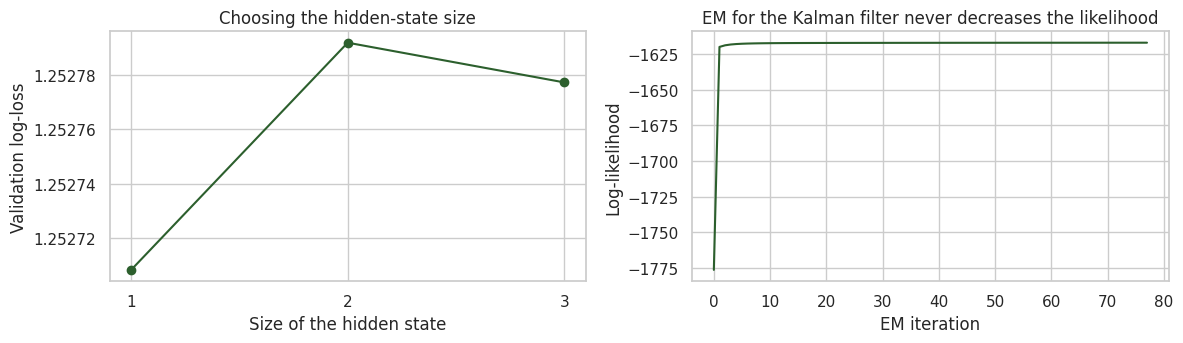

4.4 Kalman filter (linear dynamical system): best hidden_dim = 1 | validation log-loss 1.2527 | test log-loss 1.2950


,hidden_dim,cat_log_loss,cat_accuracy,cat_macro_f1,rmse_mm,mae_mm,train_loglik,n_params,em_iterations,persistence_spectral_radius_A,noise_R
0,1,1.2527,40.0,34.212,42.5943,32.6321,-1361.7331,6,90,0.7265,0.9949
1,2,1.2528,40.0,34.212,42.6040,32.6328,-1361.7067,15,133,0.9215,0.9915
2,3,1.2528,40.0,34.212,42.5818,32.6195,-1361.5859,28,150,0.8093,0.9818


In [16]:
# ==================================================================
# 4.4 Kalman filter (linear dynamical system)
# ==================================================================
class KalmanLDS:
    """Linear dynamical system: x_t = A x_(t-1) + Q-noise (hidden, d numbers); z_t = C x_t + R-noise (observed anomaly)."""

    def __init__(self, d=1, seed=0):
        rng = np.random.RandomState(seed); self.d = d
        self.A = 0.8 * np.eye(d) + 0.05 * rng.randn(d, d)
        self.C = 0.5 * rng.randn(1, d) + 0.3
        self.Q = 0.1 * np.eye(d); self.R = np.array([[0.5]])
        self.mu0 = np.zeros(d); self.P0 = np.eye(d)

    def kalman_filter(self, z):
        """Forward pass: prediction before each month, correction after it; returns the log-likelihood."""
        T, d = len(z), self.d
        xp, Pp, xf, Pf = np.zeros((T, d)), np.zeros((T, d, d)), np.zeros((T, d)), np.zeros((T, d, d))
        m, P, ll = self.mu0, self.P0, 0.0
        for t in range(T):
            xp[t], Pp[t] = m, P                                              # prediction
            S = (self.C @ P @ self.C.T + self.R).item()
            K = (P @ self.C.T) / S                                           # Kalman gain
            e = z[t] - (self.C @ m).item()                                   # innovation (surprise)
            xf[t] = m + K.ravel() * e; Pf[t] = P - K @ self.C @ P           # correction
            ll += -0.5 * (np.log(2 * np.pi * S) + e * e / S)
            m, P = self.A @ xf[t], self.A @ Pf[t] @ self.A.T + self.Q
        return xp, Pp, xf, Pf, ll

    def smoother(self, z):
        """Backward pass (Rauch-Tung-Striebel smoother)."""
        xp, Pp, xf, Pf, ll = self.kalman_filter(z); T = len(z)
        xs, Ps, J = xf.copy(), Pf.copy(), np.zeros((T, self.d, self.d))
        for t in range(T - 2, -1, -1):
            J[t] = Pf[t] @ self.A.T @ np.linalg.inv(Pp[t + 1])
            xs[t] = xf[t] + J[t] @ (xs[t + 1] - xp[t + 1])
            Ps[t] = Pf[t] + J[t] @ (Ps[t + 1] - Pp[t + 1]) @ J[t].T
        return xs, Ps, J, ll

    def fit(self, z, n_iter=150, tol=1e-6):
        """EM: E-step = smoother, M-step = closed-form updates of A, Q, C, R."""
        T = len(z); self.ll_path = []
        for it in range(n_iter):
            xs, Ps, J, ll = self.smoother(z)
            self.ll_path.append(ll)
            if it > 0 and abs(ll - self.ll_path[-2]) < tol * abs(ll):
                break
            Sxx = Ps + np.einsum('ti,tj->tij', xs, xs)                                                    # E[x_t x_t']
            Sx1 = np.einsum('tij,tkj->tik', Ps[1:], J[:-1]) + np.einsum('ti,tj->tij', xs[1:], xs[:-1])    # E[x_t x_(t-1)']
            self.A = Sx1.sum(0) @ np.linalg.inv(Sxx[:-1].sum(0))
            Q = (Sxx[1:].sum(0) - self.A @ Sx1.sum(0).T) / (T - 1); Q = (Q + Q.T) / 2
            w, V = np.linalg.eigh(Q); self.Q = (V * np.maximum(w, 1e-5)) @ V.T
            self.C = (z[:, None, None] * xs[:, None, :]).sum(0) @ np.linalg.inv(Sxx.sum(0))
            R = np.mean(z ** 2 - 2 * z * (xs @ self.C.ravel()) + np.einsum('i,tij,j->t', self.C.ravel(), Sxx, self.C.ravel()))
            self.R = np.array([[max(R, 1e-4)]]); self.mu0 = xs[0]
            w, V = np.linalg.eigh(Ps[0]); self.P0 = (V * np.maximum(w, 1e-4)) @ V.T
        self.train_ll = self.kalman_filter(z)[4]
        return self

    @property
    def n_params(self):
        d = self.d
        return d * d + d * (d + 1) + 2 * d + 1


def fit_forecast_kalman(st, c, fit_end, idx):
    z = anomalies(c)
    m = max((KalmanLDS(st['hidden_dim'], seed=s).fit(z[:fit_end]) for s in range(3)), key=lambda k: k.train_ll)
    xp, Pp, _, _, _ = m.kalman_filter(z[:idx[-1] + 1])                       # forecasts use only earlier months
    mean_z = np.array([(m.C @ xp[t]).item() for t in idx])
    var_z = np.array([(m.C @ Pp[t] @ m.C.T + m.R).item() for t in idx])
    mu = c['mu_log'][month_of[idx]] + c['sd_log'][month_of[idx]] * mean_z
    sd = c['sd_log'][month_of[idx]] * np.sqrt(var_z)
    probs = np.array([category_probs(np.array([1.0]), mu[i:i + 1], sd[i:i + 1], c['edges_log'][month_of[t]]) for i, t in enumerate(idx)])
    return dict(pt=np.exp(mu + sd ** 2 / 2) - 1, probs=probs, model=m,
                extra={'train_loglik': m.train_ll, 'n_params': m.n_params, 'em_iterations': len(m.ll_path),
                       'persistence_spectral_radius_A': float(np.abs(np.linalg.eigvals(m.A)).max()), 'noise_R': float(m.R[0, 0])})


def figures_kalman(best, r, tab):
    m = r['model']
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    ax[0].plot(tab.hidden_dim, tab.cat_log_loss, 'o-', color=PAL[0])
    ax[0].set(xlabel='Size of the hidden state', ylabel='Validation log-loss', title='Choosing the hidden-state size')
    ax[0].ticklabel_format(axis='y', useOffset=False); ax[0].set_xticks(tab.hidden_dim)
    ax[1].plot(m.ll_path, color=PAL[0])
    ax[1].set(xlabel='EM iteration', ylabel='Log-likelihood', title='EM for the Kalman filter never decreases the likelihood')
    fig.tight_layout()
    return {'kalman_filter.png': fig}


kalman_tab = tune_algorithm('4.4 Kalman filter (linear dynamical system)', [{'hidden_dim': d} for d in (1, 2, 3)],
                            fit_forecast_kalman, figures_kalman)
kalman_tab.round(4)

### 4.5 Comparison and selection: best rainfall forecaster
The best setting of each of the four algorithms is compared on the **validation log-loss** (1981-1995). The lowest wins and is registered as `rainfall-forecaster` (champion), the runner-up as challenger. Climatology is shown for reference only. Test log-loss (1996-2015) is reported next to it but not used to choose.

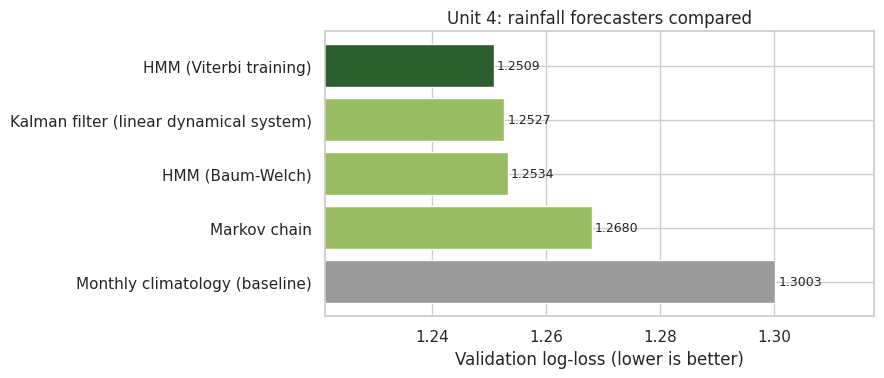

Registered rainfall-forecaster version 1 -> alias "champion"
Registered rainfall-forecaster version 2 -> alias "challenger"
CHOSEN: HMM (Viterbi training) (n_states = 2), validation log-loss 1.2509 | runner-up: Kalman filter (linear dynamical system) (1.2527)


Successfully registered model 'rainfall-forecaster'.
Created version '1' of model 'rainfall-forecaster'.
Registered model 'rainfall-forecaster' already exists. Creating a new version of this model...
Created version '2' of model 'rainfall-forecaster'.


,algorithm,best setting,val_log_loss,test_log_loss,test_accuracy,test_rmse_mm
0,HMM (Viterbi training),n_states = 2,1.2509,1.2954,36.2500,50.3920
1,Kalman filter (linear dynamical system),hidden_dim = 1,1.2527,1.2950,36.2500,50.2935
2,HMM (Baum-Welch),n_states = 2,1.2534,1.2772,37.9167,49.9636
3,Markov chain,"order = 0, seasons = 4",1.2680,1.3142,41.6667,50.9311
4,Monthly climatology (baseline),none,1.3003,1.2929,35.0000,50.5496


In [17]:
# ==================================================================
# 4.5 Comparison and selection (Unit 4)
# ==================================================================
comp4 = (pd.DataFrame([{'algorithm': a, 'best setting': r['setting'], 'val_log_loss': r['val_log_loss'],
                        'test_log_loss': r['test_cat_log_loss'], 'test_accuracy': r['test_cat_accuracy'],
                        'test_rmse_mm': r['test_rmse_mm']} for a, r in U4.items()])
           .sort_values('val_log_loss').reset_index(drop=True))
chosen4, runner4 = comp4.iloc[0], comp4.iloc[1]
table4 = pd.concat([comp4, pd.DataFrame([{'algorithm': 'Monthly climatology (baseline)', 'best setting': 'none',
                                          'val_log_loss': BASELINE4['val_log_loss'], 'test_log_loss': BASELINE4['test_cat_log_loss'],
                                          'test_accuracy': BASELINE4['test_cat_accuracy'], 'test_rmse_mm': BASELINE4['test_rmse_mm']}])],
                   ignore_index=True)

with mlflow.start_run(run_name='4.5 Comparison and selection: best rainfall forecaster') as run:
    mlflow.set_tags({'level': 'selection', 'unit': '4'})
    mlflow.log_params({'algorithms_compared': ', '.join(comp4.algorithm),
                       'selection_rule': 'lowest validation category log-loss (1981-1995)',
                       'chosen_algorithm': chosen4.algorithm, 'chosen_setting': chosen4['best setting'],
                       'runner_up': runner4.algorithm, 'baseline': 'monthly climatology'})
    mlflow.log_metrics({**{f'val_log_loss_{slug(a)}': v for a, v in zip(comp4.algorithm, comp4.val_log_loss)},
                        'val_log_loss_baseline_climatology': BASELINE4['val_log_loss'],
                        'chosen_val_log_loss': chosen4.val_log_loss, 'chosen_test_log_loss': chosen4.test_log_loss})
    mlflow.log_table(table4.astype(str), 'comparison.json')
    fig = comparison_chart(list(table4.algorithm), list(table4.val_log_loss), 'Unit 4: rainfall forecasters compared',
                           'Validation log-loss (lower is better)', baseline='Monthly climatology (baseline)')
    mlflow.log_figure(fig, 'comparison.png'); plt.show()

for row, alias in [(chosen4, 'champion'), (runner4, 'challenger')]:
    register(U4[row.algorithm]['run_id'], U4[row.algorithm]['model_uri'], 'rainfall-forecaster', alias,
             f'{row.algorithm} ({row["best setting"]}): next-month rainfall category for {SUBDIVISION}; validation log-loss {row.val_log_loss:.4f}.')
print(f'CHOSEN: {chosen4.algorithm} ({chosen4["best setting"]}), validation log-loss {chosen4.val_log_loss:.4f}'
      f' | runner-up: {runner4.algorithm} ({runner4.val_log_loss:.4f})')
table4.round(4)

---
# 5. Unit 5: Ensemble methods for crop recommendation and the potassium estimate
**Project goal.** Recommend the crop for a field (22 classes) and estimate its soil potassium K (needed for the fertiliser dose), as accurately as possible.

| Section | Algorithm | Ensemble type | Why it fits this goal | What is tuned (child runs) |
|---|---|---|---|---|
| 5.1 | **Random forest** | bagging | Averages many decorrelated trees; handles interactions between soil and weather readings | trees x inputs per split |
| 5.2 | **Extra trees** | bagging (randomised splits) | Even less correlated trees, lower variance | trees x inputs per split |
| 5.3 | **Gradient boosting** | boosting | Adds trees one at a time to fix the remaining errors | learning rate x trees |
| 5.4 | **Stacking** | model combination | Learns how far to trust different kinds of model | base models (each shown as a child run) |
| **5.5** | **Comparison and selection** | - | The four ensembles compared on one score, for each task | - |

**Score.** Mean 5-fold cross-validated **accuracy** (crop) or **R²** (potassium) on the 1,760 training fields. Ties are broken by the smaller spread across folds, then by a second CV score: the CV **log-loss** for crops (how good the predicted probabilities are) or the CV **RMSE** for potassium (lower is better). The 440 test fields are only reported. The best single model from the earlier work (Naive Bayes for crops, an RBF support-vector regressor for potassium) is logged as a **baseline** to show what ensembling adds.

### 5.0 Shared code and the single-model baselines

In [18]:
# ------------------------------------------------------------------
# Unit 5 shared code
# ------------------------------------------------------------------
mlflow.set_experiment(EXP5)
U5 = {'crop': {}, 'potassium': {}}           # best setting of each ensemble, per task -> compared in 5.5
BASELINE5 = {}
TASK = {'crop': dict(X=X_tr, y=y_tr, cv=cv, scoring='accuracy', target='crop (22 classes)', label='crop recommendation'),
        'potassium': dict(X=Xr_tr, y=yr_tr, cv=kcv, scoring='r2', target='soil potassium K', label='potassium estimate')}


def evaluate(model, task):
    """5-fold CV on the training fields (used to choose), then one fit and the test scores (reported only).
    cv_tiebreak = a second CV score, used only if two models tie on cv_mean and cv_std (lower is better):
    CV log-loss for crops (quality of the predicted probabilities), CV RMSE for potassium."""
    t = TASK[task]
    second = 'neg_log_loss' if task == 'crop' else 'neg_root_mean_squared_error'
    cvs = cross_validate(model, t['X'], t['y'], cv=t['cv'], scoring=[t['scoring'], second], n_jobs=-1)
    main, tie = cvs[f'test_{t["scoring"]}'], -cvs[f'test_{second}']
    model.fit(t['X'], t['y'])
    if task == 'crop':
        p = model.predict(X_te)
        return {'cv_mean': main.mean() * 100, 'cv_std': main.std() * 100, 'cv_tiebreak': tie.mean(), 'cv_log_loss': tie.mean(),
                'test_accuracy': accuracy_score(y_te, p) * 100, 'test_macro_f1': f1_score(y_te, p, average='macro') * 100,
                'test_wrong_of_440': int((p != y_te).sum())}
    p = model.predict(Xr_te)
    return {'cv_mean': main.mean(), 'cv_std': main.std(), 'cv_tiebreak': tie.mean(), 'cv_rmse': tie.mean(),
            'test_r2': r2_score(yr_te, p), 'test_rmse': mean_squared_error(yr_te, p) ** 0.5, 'test_mae': mean_absolute_error(yr_te, p)}


def grid_search_children(model, grid, task):
    """Every combination of grid scored by 5-fold CV, one child run each. Returns the best settings and the table."""
    t = TASK[task]; rows = []
    for combo in itertools.product(*grid.values()):
        st = dict(zip(grid, combo))
        s = cross_val_score(clone(model).set_params(**st), t['X'], t['y'], cv=t['cv'], scoring=t['scoring'], n_jobs=-1)
        short = {k.split('__')[-1]: v for k, v in st.items()}
        child(', '.join(f'{k} = {v}' for k, v in short.items()), short, {'cv_mean': s.mean(), 'cv_std': s.std()})
        rows.append({**short, 'cv_mean': s.mean(), 'cv_std': s.std(), '_st': st})
    tab = pd.DataFrame(rows)
    best_i = tab.sort_values(['cv_mean', 'cv_std'], ascending=[False, True]).index[0]
    return tab.loc[best_i, '_st'], tab.drop(columns='_st')


def log_parent(task, name, family, run, model, scores, params, store=True):
    """Parent-run bookkeeping: tags, parameters, metrics, model file; stores the result for the comparison."""
    mlflow.set_tags({'level': 'parent' if store else 'baseline', 'unit': '5', 'algorithm': name.split(' ', 1)[1].split(' (')[0],
                     'ensemble_type': family, 'task': TASK[task]['label']})
    mlflow.log_params({**SPLIT_PARAMS, 'algorithm': name, 'target': TASK[task]['target'], **params})
    mlflow.log_metrics(scores)
    info = log_sk(model, TASK[task]['X'].head(3))
    entry = {**scores, 'family': family, 'run_id': run.info.run_id, 'model_uri': info.model_uri if info else None, 'model': model}
    if store:
        U5[task][name.split(' ', 1)[1].split(' (')[0]] = entry
    else:
        BASELINE5[task] = {**entry, 'name': name.split(': ', 1)[1].split(' (')[0]}
    test = scores.get('test_accuracy', scores.get('test_r2'))
    print(f'{name:<48} CV {scores["cv_mean"]:.4f} (+/- {scores["cv_std"]:.4f}) | test {test:.4f}')


def tuned_run(run_name, task, family, model, grid, store=True):
    """Grid search with child runs, then refit the best setting and log the parent run."""
    with mlflow.start_run(run_name=run_name) as run:
        best, tab = grid_search_children(model, grid, task)
        fitted = clone(model).set_params(**best)
        scores = evaluate(fitted, task)
        params = {'tuned': ', '.join(k.split('__')[-1] for k in grid),
                  'values_tried': str({k.split('__')[-1]: v for k, v in grid.items()}),
                  **{f'best_{k.split("__")[-1]}': v for k, v in best.items()}, 'chosen_by': 'highest mean 5-fold CV score'}
        log_parent(task, run_name, family, run, fitted, scores, params, store)
        mlflow.log_table(tab.astype(str), 'settings_results.json')
    return fitted, tab


# Baselines (best single models; not part of the comparison)
nb_base, _ = tuned_run('5.0 Baseline: Naive Bayes (crop)', 'crop', 'single model', GaussianNB(),
                       {'var_smoothing': [1e-12, 1e-9, 1e-6]}, store=False)
svr_base, _ = tuned_run('5.0 Baseline: SVR, RBF kernel (potassium)', 'potassium', 'single model',
                        make_pipeline(StandardScaler(), SVR(kernel='rbf')), {'svr__C': [10, 100, 1000, 5000]}, store=False)

5.0 Baseline: Naive Bayes (crop)                 CV 99.4886 (+/- 0.4175) | test 99.5455


5.0 Baseline: SVR, RBF kernel (potassium)        CV 0.9832 (+/- 0.0020) | test 0.9844


### 5.1 Random forest (bagging)
**What it does.** Trains many decision trees, each on a bootstrap resample of the training fields, and lets each split consider only a random subset of the inputs (`max_features`). Averaging (potassium) or voting (crop) over the trees lowers the variance of a single tree.

**What is tuned.** Number of trees x `max_features`: 12 child runs for crops, 8 for potassium. The inputs used most by the forest are also shown.

5.1 Random forest (crop)                         CV 99.3750 (+/- 0.3313) | test 99.5455


5.1 Random forest (potassium)                    CV 0.9915 (+/- 0.0013) | test 0.9915


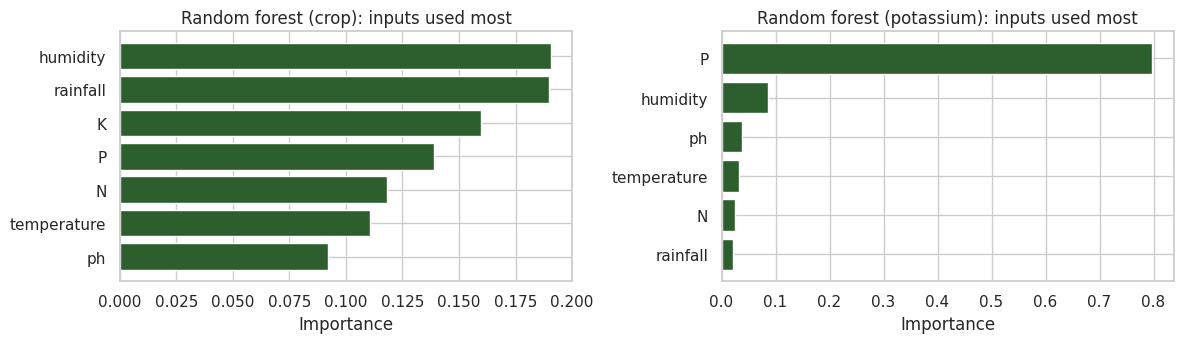

In [19]:
# ==================================================================
# 5.1 Random forest
# ==================================================================
rf = {}
rf['crop'], rf_crop_tab = tuned_run('5.1 Random forest (crop)', 'crop', 'bagging', RandomForestClassifier(random_state=SEED, n_jobs=-1),
                                    {'n_estimators': [50, 100, 300], 'max_features': [1, 2, 3, 7]})
rf['potassium'], rf_k_tab = tuned_run('5.1 Random forest (potassium)', 'potassium', 'bagging', RandomForestRegressor(random_state=SEED, n_jobs=-1),
                                      {'n_estimators': [100, 300], 'max_features': [1, 2, 3, 6]})

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, task in zip(ax, ['crop', 'potassium']):
    imp = pd.Series(rf[task].feature_importances_, index=TASK[task]['X'].columns).sort_values()
    a.barh(imp.index, imp.values, color=PAL[0]); a.set(xlabel='Importance', title=f'Random forest ({task}): inputs used most')
fig.tight_layout(); plt.show()

### 5.2 Extra trees (extremely randomised trees)
**What it does.** Like a random forest, but every split threshold is also drawn at random (and the whole training set is used for each tree). The trees are even less alike, so averaging them removes more variance.

**What is tuned.** Number of trees x `max_features`: 8 child runs per task.

In [20]:
# ==================================================================
# 5.2 Extra trees
# ==================================================================
et = {}
et['crop'], et_crop_tab = tuned_run('5.2 Extra trees (crop)', 'crop', 'bagging', ExtraTreesClassifier(random_state=SEED, n_jobs=-1),
                                    {'n_estimators': [100, 300], 'max_features': [1, 2, 3, 7]})
et['potassium'], et_k_tab = tuned_run('5.2 Extra trees (potassium)', 'potassium', 'bagging', ExtraTreesRegressor(random_state=SEED, n_jobs=-1),
                                      {'n_estimators': [100, 300], 'max_features': [1, 2, 3, 6]})

5.2 Extra trees (crop)                           CV 99.3750 (+/- 0.3313) | test 99.5455


5.2 Extra trees (potassium)                      CV 0.9927 (+/- 0.0010) | test 0.9917


### 5.3 Gradient boosting
**What it does.** Builds the ensemble **one small tree at a time**; each new tree is fitted to the errors that remain (the negative gradient of the loss), and the `learning_rate` shrinks its contribution. Boosting mainly reduces bias.

**What is tuned.** Learning rate x number of trees (10 child runs per task). To keep it fast, one model per fold is grown to the largest size and scored after every tree (staged predictions), which gives the score for every number of trees from one fit.

5.3 Gradient boosting (crop)                     CV 98.8636 (+/- 0.3112) | test 98.8636


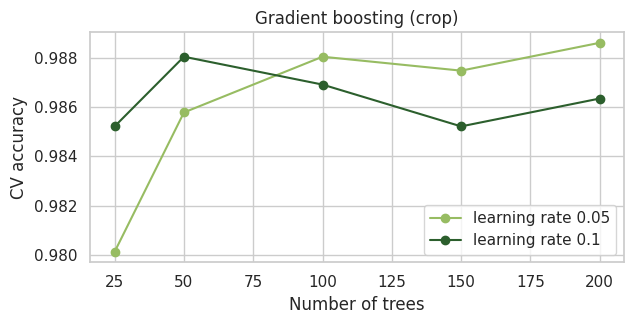

5.3 Gradient boosting (potassium)                CV 0.9867 (+/- 0.0045) | test 0.9884


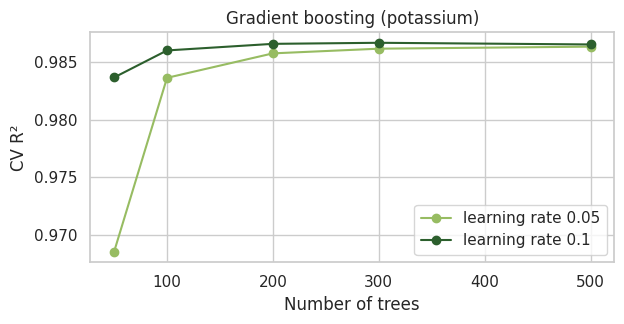

In [21]:
# ==================================================================
# 5.3 Gradient boosting
# ==================================================================
def staged_cv(make_model, task, n_list):
    """CV score after each number of trees in n_list, from ONE fit per fold (staged predictions)."""
    t = TASK[task]; out = np.zeros((t['cv'].get_n_splits(), len(n_list)))
    for f, (a, b) in enumerate(t['cv'].split(t['X'], t['y'])):
        model = make_model().fit(t['X'].iloc[a], t['y'].iloc[a])
        preds = list(model.staged_predict(t['X'].iloc[b]))
        for i, n in enumerate(n_list):
            p = preds[n - 1]
            out[f, i] = accuracy_score(t['y'].iloc[b], p) if task == 'crop' else r2_score(t['y'].iloc[b], p)
    return out.mean(0), out.std(0)


GB_SPECS = {'crop': (lambda lr, n: GradientBoostingClassifier(n_estimators=n, learning_rate=lr, max_depth=3, random_state=SEED),
                     [0.05, 0.1], [25, 50, 100, 150, 200]),
            'potassium': (lambda lr, n: GradientBoostingRegressor(n_estimators=n, learning_rate=lr, max_depth=4, random_state=SEED),
                          [0.05, 0.1], [50, 100, 200, 300, 500])}
gb = {}
for task, (make, rates, n_list) in GB_SPECS.items():
    with mlflow.start_run(run_name=f'5.3 Gradient boosting ({task})') as run:
        rows = []
        for lr in rates:                                            # one child run per (learning rate, number of trees)
            mean, std = staged_cv(lambda: make(lr, max(n_list)), task, n_list)
            for n, m_, s_ in zip(n_list, mean, std):
                child(f'learning_rate = {lr}, n_estimators = {n}', {'learning_rate': lr, 'n_estimators': n}, {'cv_mean': m_, 'cv_std': s_})
                rows.append({'learning_rate': lr, 'n_estimators': n, 'cv_mean': m_, 'cv_std': s_})
        tab = pd.DataFrame(rows)
        best = tab.sort_values(['cv_mean', 'cv_std'], ascending=[False, True]).iloc[0]
        gb[task] = make(float(best.learning_rate), int(best.n_estimators))
        scores = evaluate(gb[task], task)
        log_parent(task, f'5.3 Gradient boosting ({task})', 'boosting', run, gb[task], scores,
                   {'tuned': 'learning_rate, n_estimators', 'learning_rates_tried': str(rates), 'n_estimators_tried': str(n_list),
                    'best_learning_rate': float(best.learning_rate), 'best_n_estimators': int(best.n_estimators),
                    'chosen_by': 'highest mean 5-fold CV score'})
        fig, ax = plt.subplots(figsize=(6.5, 3.4))
        for lr, colour in zip(rates, [PAL[1], PAL[0]]):
            d = tab[tab.learning_rate == lr]; ax.plot(d.n_estimators, d.cv_mean, 'o-', color=colour, label=f'learning rate {lr}')
        ax.set(xlabel='Number of trees', ylabel='CV accuracy' if task == 'crop' else 'CV R²', title=f'Gradient boosting ({task})')
        ax.legend(); fig.tight_layout(); mlflow.log_figure(fig, 'boosting_curve.png'); plt.show()

### 5.4 Stacking
**What it does.** Combines *different kinds* of model. Each base model makes **out-of-fold** predictions (it never predicts fields it was trained on), and a second-level model learns from them how far to trust each base model.
- **Crop:** Naive Bayes, the random forest from 5.1, an RBF support-vector machine and logistic regression (C of the last two chosen by 5-fold CV); logistic regression on top.
- **Potassium:** the random forest from 5.1, the gradient boosting model from 5.3 and the RBF support-vector regressor; a non-negative linear regression on top.

**In MLflow.** Each base model's own CV score is a child run, and the learned trust (meta-weight) of each base model is logged in the parent run.

In [22]:
# ==================================================================
# 5.4 Stacking
# ==================================================================
svm = GridSearchCV(make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED)),
                   {'svc__C': [1, 10, 100]}, cv=cv, n_jobs=-1).fit(X_tr, y_tr)
logreg = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                      {'logisticregression__C': [1, 10, 100]}, cv=cv, n_jobs=-1).fit(X_tr, y_tr)

BASE = {'crop': [('naive_bayes', clone(nb_base)), ('random_forest', clone(rf['crop'])),
                 ('svm_rbf', clone(svm.best_estimator_)), ('logistic_regression', clone(logreg.best_estimator_))],
        'potassium': [('random_forest', clone(rf['potassium'])), ('gradient_boosting', clone(gb['potassium'])),
                      ('svr_rbf', clone(svr_base))]}
STACK = {'crop': StackingClassifier(BASE['crop'], final_estimator=LogisticRegression(max_iter=5000), cv=5, n_jobs=-1),
         'potassium': StackingRegressor(BASE['potassium'], final_estimator=LinearRegression(positive=True), cv=5, n_jobs=-1)}

for task in ['crop', 'potassium']:
    t = TASK[task]
    with mlflow.start_run(run_name=f'5.4 Stacking ({task})') as run:
        for name, model in BASE[task]:                               # child run per base model: its own CV score
            s = cross_val_score(clone(model), t['X'], t['y'], cv=t['cv'], scoring=t['scoring'], n_jobs=-1)
            child(f'base model: {name}', {'base_model': name}, {'cv_mean': s.mean(), 'cv_std': s.std()})
        stack = STACK[task]
        scores = evaluate(stack, task)
        coef = stack.final_estimator_.coef_
        w = (np.abs(coef).reshape(len(stack.classes_), len(BASE[task]), -1).mean(axis=(0, 2)) if task == 'crop' else np.asarray(coef))
        scores.update({f'meta_weight_{n}': float(v / w.sum()) for (n, _), v in zip(BASE[task], w)})
        log_parent(task, f'5.4 Stacking ({task})', 'model combination', run, stack, scores,
                   {'base_models': ', '.join(n for n, _ in BASE[task]),
                    'meta_model': 'logistic regression' if task == 'crop' else 'non-negative linear regression',
                    'meta_model_input': '5-fold out-of-fold predictions',
                    **({'svm_C': svm.best_params_['svc__C'], 'logistic_C': logreg.best_params_['logisticregression__C']} if task == 'crop' else {})})
    print('   meta-weights:', {k.replace('meta_weight_', ''): round(v, 3) for k, v in scores.items() if k.startswith('meta_weight')})

5.4 Stacking (crop)                              CV 99.3750 (+/- 0.3313) | test 99.3182
   meta-weights: {'naive_bayes': 0.276, 'random_forest': 0.239, 'svm_rbf': 0.227, 'logistic_regression': 0.259}


5.4 Stacking (potassium)                         CV 0.9915 (+/- 0.0012) | test 0.9914
   meta-weights: {'random_forest': 0.884, 'gradient_boosting': 0.05, 'svr_rbf': 0.066}


### 5.5 Comparison and selection: best ensemble for each task
For each task the four ensembles are ranked by mean 5-fold CV score; ties are broken by the smaller spread across folds, then by the CV log-loss (crop) or CV RMSE (potassium). The best is registered as champion (`crop-recommender`, `potassium-estimator`) and the runner-up as challenger. The single-model baseline is shown in grey for reference.

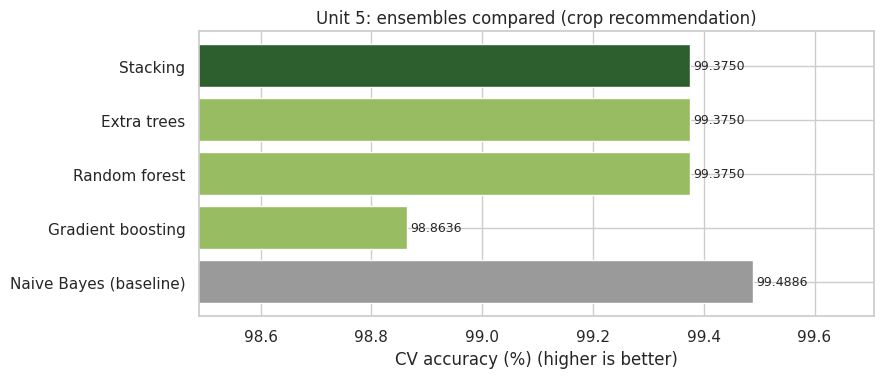

Registered crop-recommender version 1 -> alias "champion"
Registered crop-recommender version 2 -> alias "challenger"
CROP: CHOSEN Stacking (CV 99.3750, std 0.3313, cv_log_loss 0.0450) | runner-up Extra trees (CV 99.3750) | baseline Naive Bayes (CV 99.4886)



Successfully registered model 'crop-recommender'.
Created version '1' of model 'crop-recommender'.
Registered model 'crop-recommender' already exists. Creating a new version of this model...
Created version '2' of model 'crop-recommender'.


,algorithm,ensemble type,cv_mean,cv_std,cv_log_loss,test_accuracy,test_wrong_of_440
0,Stacking,model combination,99.3750,0.3313,0.0450,99.3182,3
1,Extra trees,bagging,99.3750,0.3313,0.1068,99.5455,2
2,Random forest,bagging,99.3750,0.3313,0.1448,99.5455,2
3,Gradient boosting,boosting,98.8636,0.3112,0.0478,98.8636,5
4,Naive Bayes (baseline),single model,99.4886,0.4175,0.0158,99.5455,2


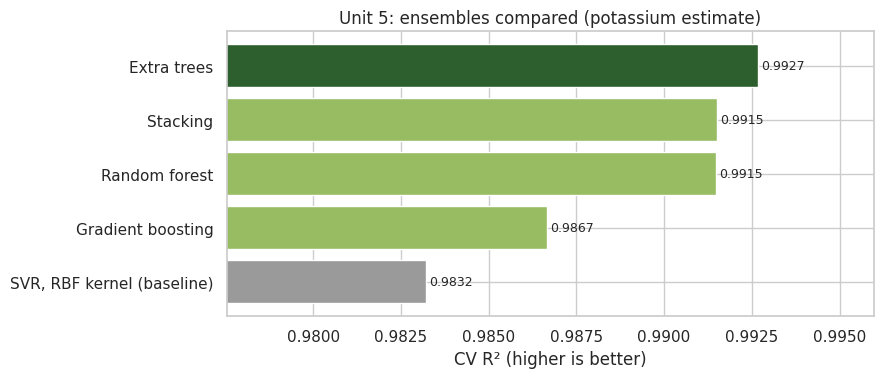

Registered potassium-estimator version 1 -> alias "champion"
Registered potassium-estimator version 2 -> alias "challenger"
POTASSIUM: CHOSEN Extra trees (CV 0.9927, std 0.0010, cv_rmse 4.2913) | runner-up Stacking (CV 0.9915) | baseline SVR, RBF kernel (CV 0.9832)



Successfully registered model 'potassium-estimator'.
Created version '1' of model 'potassium-estimator'.
Registered model 'potassium-estimator' already exists. Creating a new version of this model...
Created version '2' of model 'potassium-estimator'.


,algorithm,ensemble type,cv_mean,cv_std,cv_rmse,test_r2,test_rmse
0,Extra trees,bagging,0.9927,0.0010,4.2913,0.9917,4.5827
1,Stacking,model combination,0.9915,0.0012,4.6214,0.9914,4.6862
2,Random forest,bagging,0.9915,0.0013,4.6283,0.9915,4.6476
3,Gradient boosting,boosting,0.9867,0.0045,5.7228,0.9884,5.4282
4,"SVR, RBF kernel (baseline)",single model,0.9832,0.0020,6.5011,0.9844,6.2870


In [23]:
# ==================================================================
# 5.5 Comparison and selection (Unit 5)
# ==================================================================
SELECTED5 = {}
for task, reg_name, metric in [('crop', 'crop-recommender', 'CV accuracy (%)'), ('potassium', 'potassium-estimator', 'CV R²')]:
    test_cols = ['test_accuracy', 'test_wrong_of_440'] if task == 'crop' else ['test_r2', 'test_rmse']
    tie_col = 'cv_log_loss' if task == 'crop' else 'cv_rmse'
    comp = (pd.DataFrame([{'algorithm': a, 'ensemble type': r['family'], 'cv_mean': r['cv_mean'], 'cv_std': r['cv_std'],
                           tie_col: r[tie_col], **{c: r[c] for c in test_cols}} for a, r in U5[task].items()])
              .sort_values(['cv_mean', 'cv_std', tie_col], ascending=[False, True, True]).reset_index(drop=True))
    chosen, runner = comp.iloc[0], comp.iloc[1]
    b = BASELINE5[task]
    table = pd.concat([comp, pd.DataFrame([{'algorithm': f'{b["name"]} (baseline)', 'ensemble type': 'single model',
                                            'cv_mean': b['cv_mean'], 'cv_std': b['cv_std'], tie_col: b[tie_col], **{c: b[c] for c in test_cols}}])],
                      ignore_index=True)

    with mlflow.start_run(run_name=f'5.5 Comparison and selection: {TASK[task]["label"]}') as run:
        mlflow.set_tags({'level': 'selection', 'unit': '5', 'task': TASK[task]['label']})
        mlflow.log_params({'algorithms_compared': ', '.join(comp.algorithm),
                           'selection_rule': f'highest mean 5-fold {metric}; ties: smaller CV standard deviation, then lower {tie_col}',
                           'chosen_algorithm': chosen.algorithm, 'runner_up': runner.algorithm, 'baseline': b['name']})
        mlflow.log_metrics({**{f'cv_{slug(a)}': v for a, v in zip(comp.algorithm, comp.cv_mean)},
                            **{f'{tie_col}_{slug(a)}': v for a, v in zip(comp.algorithm, comp[tie_col])},
                            'cv_baseline': b['cv_mean'], 'chosen_cv_mean': chosen.cv_mean})
        mlflow.log_table(table.astype(str), 'comparison.json')
        fig = comparison_chart(list(table.algorithm), list(table.cv_mean), f'Unit 5: ensembles compared ({TASK[task]["label"]})',
                               f'{metric} (higher is better)', baseline=f'{b["name"]} (baseline)')
        mlflow.log_figure(fig, 'comparison.png'); plt.show()

    for row, alias in [(chosen, 'champion'), (runner, 'challenger')]:
        r = U5[task][row.algorithm]
        register(r['run_id'], r['model_uri'], reg_name, alias, f'{row.algorithm}: {metric} {row.cv_mean:.4f}.')
    SELECTED5[task] = {'chosen': chosen, 'runner': runner, 'table': table}
    print(f'{task.upper()}: CHOSEN {chosen.algorithm} (CV {chosen.cv_mean:.4f}, std {chosen.cv_std:.4f}, {tie_col} {chosen[tie_col]:.4f})'
          f' | runner-up {runner.algorithm} (CV {runner.cv_mean:.4f}) | baseline {b["name"]} (CV {b["cv_mean"]:.4f})\n')
    display(table.round(4))

---
# 6. The chosen models, loaded back from the MLflow Model Registry
One table with the algorithms compared and the one chosen in each unit; then the registered champions are loaded **by name and alias** and give one field a crop, a potassium estimate and a fertiliser zone.

In [24]:
# ==================================================================
# 6. Summary of the choices and the Model Registry
# ==================================================================
summary = pd.DataFrame([
    {'unit': 3, 'project output': 'fertiliser zones', 'algorithms compared': ', '.join(comp3.algorithm),
     'chosen': f'{chosen3.algorithm} ({chosen3["best setting"]})', 'score': f'ARI {chosen3.ari_vs_hidden_label:.3f}',
     'registered as': 'soil-zone-clusterer'},
    {'unit': 4, 'project output': 'next month rainfall category', 'algorithms compared': ', '.join(comp4.algorithm),
     'chosen': f'{chosen4.algorithm} ({chosen4["best setting"]})', 'score': f'validation log-loss {chosen4.val_log_loss:.4f}',
     'registered as': 'rainfall-forecaster'},
    *[{'unit': 5, 'project output': TASK[t]['label'], 'algorithms compared': ', '.join(s['table'].algorithm.iloc[:-1]),
       'chosen': s['chosen'].algorithm, 'score': f'CV {s["chosen"].cv_mean:.4f}',
       'registered as': 'crop-recommender' if t == 'crop' else 'potassium-estimator'} for t, s in SELECTED5.items()]])
pd.set_option('display.max_colwidth', 120)
display(summary)

counts = {e: len(mlflow.search_runs(experiment_names=[e])) for e in [EXP3, EXP4, EXP5]}
print('Runs per experiment:', counts, '| total:', sum(counts.values()))
registry = [{'registered model': rm.name, 'version': int(v.version),
             'aliases': ', '.join(client.get_model_version(rm.name, v.version).aliases), 'description': v.description}
            for rm in client.search_registered_models() for v in client.search_model_versions(f"name='{rm.name}'")]
display(pd.DataFrame(registry).sort_values(['registered model', 'version']))

# Load the champions by name and alias, and use them on one test field
crop_model = mlflow.sklearn.load_model('models:/crop-recommender@champion')
k_model = mlflow.sklearn.load_model('models:/potassium-estimator@champion')
zone_model = mlflow.sklearn.load_model('models:/soil-zone-clusterer@champion')
field = X_te.iloc[[0]]
print('Field readings      :', field.to_dict('records')[0])
print('Recommended crop    :', crop_model.predict(field)[0], '| actual:', y_te.iloc[0])
print(f'Estimated potassium : {k_model.predict(Xr.loc[field.index])[0]:.1f} | measured: {crop.loc[field.index[0], "K"]}')
print('Fertiliser zone of the first soil test:', zone_model.predict(Z[:1])[0], '| zone profiles in section 3.4')

,unit,project output,algorithms compared,chosen,score,registered as
0,3,fertiliser zones,"Hierarchical clustering, K-means, Gaussian mixture model (EM)","Hierarchical clustering (complete linkage, euclidean)",ARI 0.503,soil-zone-clusterer
1,4,next month rainfall category,"HMM (Viterbi training), Kalman filter (linear dynamical system), HMM (Baum-Welch), Markov chain",HMM (Viterbi training) (n_states = 2),validation log-loss 1.2509,rainfall-forecaster
2,5,crop recommendation,"Stacking, Extra trees, Random forest, Gradient boosting",Stacking,CV 99.3750,crop-recommender
3,5,potassium estimate,"Extra trees, Stacking, Random forest, Gradient boosting",Extra trees,CV 0.9927,potassium-estimator


Runs per experiment: {'Unit 3 - Clustering': 28, 'Unit 4 - Sequential models (HMM)': 28, 'Unit 5 - Ensemble methods': 82} | total: 138


,registered model,version,aliases,description
1,crop-recommender,1,champion,Stacking: CV accuracy (%) 99.3750.
0,crop-recommender,2,challenger,Extra trees: CV accuracy (%) 99.3750.
3,potassium-estimator,1,champion,Extra trees: CV R² 0.9927.
2,potassium-estimator,2,challenger,Stacking: CV R² 0.9915.
5,rainfall-forecaster,1,champion,HMM (Viterbi training) (n_states = 2): next-month rainfall category for TAMIL NADU; validation log-loss 1.2509.
4,rainfall-forecaster,2,challenger,Kalman filter (linear dynamical system) (hidden_dim = 1): next-month rainfall category for TAMIL NADU; validation lo...
6,soil-zone-clusterer,1,champion,"Hierarchical clustering (complete linkage, euclidean) on standardised N, P, K, served by a nearest-centroid rule; AR..."


Field readings      : {'N': 13, 'P': 23, 'K': 6, 'temperature': 23.96147583, 'humidity': 90.26408017, 'ph': 7.365338111, 'rainfall': 102.6958703}


Recommended crop    : orange | actual: orange
Estimated potassium : 15.5 | measured: 6
Fertiliser zone of the first soil test: 3 | zone profiles in section 3.4


### Where to find the comparison in the MLflow UI
Start the dashboard from this folder with `mlflow ui --backend-store-uri sqlite:///mlflow.db` and open http://localhost:5000.

| Experiment | Algorithm runs (expand + for the settings tried) | Comparison and selection run |
|---|---|---|
| `Unit 3 - Clustering` | 3.1 K-means, 3.2 Hierarchical clustering, 3.3 Gaussian mixture model (EM) | **3.4 Comparison and selection: best clustering algorithm** |
| `Unit 4 - Sequential models (HMM)` | 4.1 Markov chain, 4.2 HMM (Baum-Welch), 4.3 HMM (Viterbi training), 4.4 Kalman filter; 4.0 baseline | **4.5 Comparison and selection: best rainfall forecaster** |
| `Unit 5 - Ensemble methods` | 5.1 Random forest, 5.2 Extra trees, 5.3 Gradient boosting, 5.4 Stacking (crop and potassium); 5.0 baselines | **5.5 Comparison and selection: crop recommendation / potassium estimate** |

- In each selection run: **Parameters** show the algorithms compared, the rule and the chosen algorithm; **Metrics** show every algorithm's score; **Artifacts** hold `comparison.png` and `comparison.json`.
- To compare the algorithms side by side: in an experiment, filter with `tags.level = "parent"`, tick the runs, and click **Compare**.
- Search filters: `tags.level = "selection"` (only the choices), `tags.chosen = "yes"` (only the chosen algorithms).
- **Models** page: `soil-zone-clusterer`, `rainfall-forecaster`, `crop-recommender`, `potassium-estimator`, with aliases *champion* and *challenger*.